# x50 データの前処理から再帰予測まで（グローバルモデル: Y1〜Y10 を1つのモデルで、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-21
- **目的**: 生データ（列 `date`, `Y1`〜`Y10`, `X1`〜`X50`）の前処理・特徴量エンジニアリングから、目的変数 Y1〜Y10 を
  **1つのモデル（グローバルモデル）** で学習、テスト期間（2025年）の再帰予測、評価（MAE）、SHAP によるモデル解釈までを
  1つのノートブックで行い、目的変数ごとの個別モデル（004 / 006）と比べる。
  `003_feature_engineering_x50.ipynb`（前半）と `005_train_predict_x50_global.ipynb`（後半）を合わせたもの。
- **入力**（ダミー。`scripts/generate_dummy_x50.py` で作成）
  - 学習: `data/synthetic/x50/dummy_x50_train.csv`（2022-01-01〜2024-12-31）
  - テスト: `data/synthetic/x50/dummy_x50_test.csv`（2025-01-01〜2025-12-31、目的変数なし）
  - 正解: `data/synthetic/x50/dummy_x50_test_answer.csv`（予測の評価だけに使う）
- **出力**
  - 前処理済みの CSV: `data/processed/x50/x50_train_features.csv`, `x50_test_features.csv`（後半の入力）
  - `outputs/experiments/x50_global_{モデル名}/{実行日時}/`（予測・MAE の表・図・SHAP・ログ）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **スクリプト版**: 後半の処理は `scripts/train_predict_x50_global.py`（CLI）と同じ関数を使う。このノートブックは `scripts/` を
  import せず、同じ関数をノートブック内（「関数の定義」）で定義している

**グローバルモデルとは:** 学習データを縦持ち（1行 = 日付 × 目的変数）にし、目的変数の種類を表す系列ID（列 `series`）を
特徴量に加えて、全目的変数の行で1つのモデルを学習する。データを共有できる（似た動きの目的変数から学べる）一方、
目的変数ごとに効く説明変数が違う場合は、その違いを「系列ID × 説明変数」の組み合わせとして学ぶ必要がある。

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理（前半） | 値を学習する前処理（べき変換の λ・スケーリングの中央値と四分位範囲・経過日数の基準日・べき変換する列の判定）は学習データだけで fit し、テストデータには `transform` だけをかける。系列IDの整数化（`PandasOrdinalEncoder`）だけは、後半で CV の各 fold の学習期間で fit する | 4. 前処理のリークの確認 / `modeling` の Pipeline |
| 目的変数の特徴量（前半） | 学習データのラグ・移動平均・前日比は、各目的変数自身の t − 1 日以前の実測値だけから作る。テスト期間の分は前処理では作らない | 4. 前処理のリークの確認 |
| 入力（後半） | 前処理済みのテストデータに、どの目的変数（`Yk`・`Yk_raw`）も、その特徴量（`Yk_lag_*`）も無いこと | 5. 読み込み（`load_inputs`） |
| 縦持ち | 目的変数の特徴量は系列（目的変数）ごとに作る。各行の特徴量は**その行の目的変数自身**のラグ等だけで、他の目的変数の値は混ざらない。系列ごとに作り直した値が、前半で目的変数ごとに作ったCSVの値と一致することを確かめる | 6. 縦持ちとリークの確認（`prepare`） |
| 再帰予測 | 検証・テスト期間は**再帰予測の中で**、全系列を1日ずつ同時に進めながら予測値から作り直す | 再帰予測のリークの確認 |
| CV | 日付で区切る時系列CV（全系列で同じ境目）。境目より前だけで学習し、境目以降を**実測値を使わずに**再帰予測して評価する | 6. の fold の期間の確認 |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | 7. `collect_predictions` |

In [1]:
import datetime as dt
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.pipeline import Pipeline

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from feature_engineering.datetime_features import (  # noqa: E402
    CyclicalFeaturesEncoder,
    DatetimeFeaturesExtractor,
    ElapsedTimeTransformer,
)
from feature_engineering.numeric import LogTransformer, PandasPowerTransformer  # noqa: E402
from feature_engineering.scaling import PandasRobustScaler  # noqa: E402
from modeling.config import ExperimentConfig, ForecastConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import (  # noqa: E402
    ForecastCVResult,
    TargetFeatureBuilder,
    make_builder,
    recursive_forecast,
)
from modeling.metrics import get_metric  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

# pandas の表示で列を省略しすぎないようにする
pd.set_option("display.max_columns", 30)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/007_pipeline_x50_global.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGET_COLS: [Y1, Y2, Y3], DETAIL_TARGET: Y2}"
```

In [2]:
# --- 入力・出力（data/ からの相対パス） ---
RAW_TRAIN_PATH = "synthetic/x50/dummy_x50_train.csv"  # 学習データ（date, Y1〜Y10, X1〜X50）
RAW_TEST_PATH = "synthetic/x50/dummy_x50_test.csv"  # テストデータ（date, X1〜X50。目的変数なし）
RAW_ANSWER_PATH = "synthetic/x50/dummy_x50_test_answer.csv"  # テストの正解（None なら評価しない）
FEATURES_DIR = "processed/x50"  # 前処理済みの CSV の出力先（後半の学習の入力になる）

# --- 前処理・特徴量エンジニアリング ---
DATE_COL = "date"  # 日付
TARGET_COLS = [f"Y{k}" for k in range(1, 11)]  # 目的変数
FEATURE_COLS = None  # 説明変数（None なら日付・目的変数以外の全列）
# 目的変数の特徴量（全目的変数で同じ定義。再帰予測でも同じ定義で作る）
TARGET_LAGS = [1, 2, 3, 7, 14, 28]  # ラグ（日数。1以上）
ROLLING_WINDOWS = [7, 28]  # 前日までの移動平均の窓幅（日数）
RATE_OF_CHANGE = True  # 前日の前日比を加えるか
# 目的変数の変換（"log" または None）。後半の学習も対数で行う（"log" 以外は後半と合わない）
TARGET_TRANSFORM = "log"
TARGET_LOG_OFFSET = 0.0
DATE_COMPONENTS = ["year", "month", "day", "weekday", "week"]  # 日付から取り出す成分
# 学習データの歪度の絶対値がこれを超える説明変数は、べき変換（Yeo-Johnson）で分布を整える
SKEW_THRESHOLD = 1.0

# --- 学習・再帰予測 ---
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
DETAIL_TARGET = "Y1"  # 詳しい図を表示する目的変数
N_TRIALS = 0  # Optuna の試行回数（0 ならチューニングしない）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）
COMPARE_WITH_004 = True  # 個別モデル（004 / 006）の最新の結果と比べるか

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50_global.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
入力の読み込み・確認と図の部品は、004（`scripts/train_predict_x50.py`）と同じ関数。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

前半の前処理（`Preprocessor` など）は、前半の各節の中で定義する。日付の列名 `DATE_COL` は、スクリプトでは定数だが、このノートブックではパラメータのセルで定義する。

### 定数と結果の入れ物

入出力のパス・列名・CVの境目の既定値（004 と同じ）、縦持ちの表の系列ID・目的変数の列名（`series`・`value`）、
リークのおそれを表すエラー（`LeakageError`）と、読み込んだ入力（`Inputs`）・グローバルモデルの結果（`GlobalRun`）を
まとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Yk_raw`）


PRED_COL = "pred"  # 目的変数ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"
SERIES_COL = "series"  # 縦持ちの表で、目的変数の種類（Y1〜Y10）を表す系列ID


VALUE_COL = "value"  # 縦持ちの表の目的変数（元の尺度）


logger = logging.getLogger("train_predict_x50_global")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、1つの目的変数から作った特徴量の定義（列名から読み取る）。

    Attributes:
        target: 目的変数の列名（例: `Y1`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力。

    Attributes:
        train: 学習データのCSV（日付の昇順）。
        test: テストデータのCSV（日付の昇順）。
        targets: 目的変数の列名（CSVの並び順）。
        specs: 目的変数 → その目的変数の特徴量の定義。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全目的変数のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    targets: list[str]
    specs: dict[str, TargetFeatureSpec]
    exog_cols: list[str]


@dataclass
class GlobalRun:
    """グローバルモデルの学習・予測の結果。

    Attributes:
        targets: 目的変数（系列）の並び。
        dataset: 学習用データ一式（縦持ち）。
        result: `run_experiment` の結果。
        predictions: テスト予測（縦持ち。列 `date`, `series`, `pred`。正解があれば `actual` も）。
        oof: 学習期間の OOF 予測
            （縦持ち。列 `date`, `series`, `actual`, `pred`, `onestep`, `fold`）。
    """

    targets: list[str]
    dataset: Dataset
    result: ExperimentResult
    predictions: pd.DataFrame
    oof: pd.DataFrame

In [4]:
# このノートブックでは、前半（1〜4）で作る前処理済みの CSV を後半の入力にする
# （上のセルはスクリプトと同じ既定値。パラメータで指定した出力先に置き換える）
TRAIN_PATH = data_dir() / FEATURES_DIR / "x50_train_features.csv"
TEST_PATH = data_dir() / FEATURES_DIR / "x50_test_features.csv"
ANSWER_PATH = None if RAW_ANSWER_PATH is None else data_dir() / RAW_ANSWER_PATH

### ログ（004 と同じ）

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [5]:
def setup_logging(log_path: Path, level: int = logging.INFO) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    root = logging.getLogger()
    root.setLevel(level)
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    handlers: list[logging.Handler] = [
        logging.FileHandler(log_path, encoding="utf-8"),
        logging.StreamHandler(sys.stdout),
    ]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認（004 と同じ）

学習データの列から目的変数（`Yk` と `Yk_raw` の組）と、その特徴量の定義を読み取り、テストデータに目的変数や
その特徴量が無いこと・学習とテストで特徴量の列が同じこと・日付が1日刻みで続いていることを確かめる（`load_inputs`）。

In [6]:
def detect_targets(columns: Sequence[str]) -> list[str]:
    """学習データの列から目的変数を見つける（`Yk` と `Yk_raw` の両方がある列 `Yk`）。"""
    return [c for c in columns if f"{c}{RAW_SUFFIX}" in columns]


def parse_target_features(columns: Sequence[str], target: str) -> TargetFeatureSpec:
    """列名から、1つの目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """日付が1日刻みで、重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    gaps = frame[DATE_COL].diff().dropna()
    if frame[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
        raise ValueError(f"{name}の日付が1日刻みになっていません（重複または欠け）")


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    targets: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータを読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、どの目的変数も・目的変数から作った特徴量も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。
        - どちらも1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        targets: 予測する目的変数（Noneなら学習データの全目的変数）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
    test = read_csv_auto(test_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    all_targets = detect_targets(list(train.columns))
    if not all_targets:
        raise ValueError(f"学習データに目的変数（Yk と Yk{RAW_SUFFIX} の組）がありません")
    leaked = [
        c
        for c in test.columns
        if any(c == t or c == f"{t}{RAW_SUFFIX}" or c.startswith(f"{t}_") for t in all_targets)
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")
    unknown = [t for t in targets or [] if t not in all_targets]
    if unknown:
        raise ValueError(f"学習データに無い目的変数です: {unknown}（あるのは {all_targets}）")

    columns = list(train.columns)
    specs = {t: parse_target_features(columns, t) for t in all_targets}
    target_cols = {c for t in all_targets for c in (t, f"{t}{RAW_SUFFIX}", *specs[t].columns)}
    exog_cols = [c for c in columns if c != DATE_COL and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end, test_start = train[DATE_COL].max(), test[DATE_COL].min()
    if test_start != train_end + pd.Timedelta(days=1):
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていません: {train_end} → {test_start}"
        )
    selected = list(targets) if targets else all_targets
    first = specs[selected[0]]
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train_end:%Y-%m-%d}",
        f"{test_start:%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数: %s", selected)
    logger.info(
        "特徴量（目的変数ごと）: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "再帰予測で作り直す）, 日付・説明変数 %d列",
        len(first.columns),
        first.lags,
        first.rolling_windows,
        first.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, *exog_cols]],
        targets=selected,
        specs={t: specs[t] for t in selected},
        exog_cols=exog_cols,
    )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer

### 縦持ちへの変換

- `common_spec`: 全目的変数で共通の、目的変数の特徴量の定義（列名は `value_lag_1` など）。定義が目的変数によって違えば
  1つのモデルで扱えないためエラーにする。
- `to_long`: 学習・テストのデータを縦持ち（1行 = 日付 × 目的変数）にする。CSVにある目的変数の特徴量は外し、
  `modeling` に系列ごとに作り直させる。
- `csv_target_features`: CSVにある目的変数の特徴量を縦持ちにする（作り直した値との照合に使う）。

In [7]:
def common_spec(inputs: Inputs) -> TargetFeatureSpec:
    """全目的変数で共通の、目的変数の特徴量の定義を返す（列名は `value_lag_1` など）。

    Raises:
        ValueError: 目的変数によって特徴量の定義（ラグ・窓幅）が違う場合（1つのモデルで扱えない）。
    """
    specs = [inputs.specs[t] for t in inputs.targets]
    first = specs[0]
    for spec in specs[1:]:
        if (spec.lags, spec.rolling_windows, spec.rate_of_change) != (
            first.lags,
            first.rolling_windows,
            first.rate_of_change,
        ):
            raise ValueError(f"{spec.target} の特徴量の定義が {first.target} と違います")
    columns = [f"{VALUE_COL}{c[len(first.target) :]}" for c in first.columns]
    return TargetFeatureSpec(
        VALUE_COL, first.lags, first.rolling_windows, first.rate_of_change, columns
    )


def to_long(inputs: Inputs) -> tuple[pd.DataFrame, pd.DataFrame]:
    """学習・テストのデータを縦持ち（1行 = 日付 × 目的変数）にする。

    学習の表は「日付・系列ID・日付の特徴量・説明変数・目的変数（元の尺度）」だけにする。
    CSVにある目的変数の特徴量は外し、`modeling` に系列ごとに作り直させる
    （テスト期間は再帰予測の中で作る）。
    行は日付の昇順、同じ日付の中は目的変数の並び順。

    Returns:
        (学習の表, テストの表（目的変数なし）)。
    """
    train_parts, test_parts = [], []
    for target in inputs.targets:
        part = inputs.train[[DATE_COL, *inputs.exog_cols]].copy()
        part[SERIES_COL] = target
        part[VALUE_COL] = inputs.train[f"{target}{RAW_SUFFIX}"]
        train_parts.append(part)
        test_parts.append(inputs.test[[DATE_COL, *inputs.exog_cols]].assign(**{SERIES_COL: target}))
    columns = [DATE_COL, SERIES_COL, *inputs.exog_cols]
    train = pd.concat(train_parts, ignore_index=True)[[*columns, VALUE_COL]]
    test = pd.concat(test_parts, ignore_index=True)[columns]
    order = {t: i for i, t in enumerate(inputs.targets)}
    keys = [DATE_COL, SERIES_COL]
    train = train.sort_values(keys, key=lambda s: s.map(order) if s.name == SERIES_COL else s)
    test = test.sort_values(keys, key=lambda s: s.map(order) if s.name == SERIES_COL else s)
    assert VALUE_COL not in test.columns
    return train.reset_index(drop=True), test.reset_index(drop=True)


def csv_target_features(inputs: Inputs, spec: TargetFeatureSpec) -> pd.DataFrame:
    """学習データのCSVにある目的変数の特徴量を縦持ちにする（列名は `value_lag_1` などに揃える）。"""
    parts = []
    for target in inputs.targets:
        own = inputs.specs[target].columns
        part = inputs.train[[DATE_COL, *own]].rename(
            columns=dict(zip(own, spec.columns, strict=True))
        )
        parts.append(part.assign(**{SERIES_COL: target}))
    return pd.concat(parts, ignore_index=True)

### 実験設定

グローバルモデルの `modeling.config.ExperimentConfig` を作る。系列IDの整数化（`PandasOrdinalEncoder`。CVの fold ごとに
学習期間で fit）、系列ごとに作る再帰予測の特徴量（`forecast.series_col`）、目的変数の対数変換などを含む。

In [8]:
def make_config(
    model: str,
    spec: TargetFeatureSpec,
    n_series: int,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
) -> ExperimentConfig:
    """グローバルモデルの実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        spec: 目的変数の特徴量の定義（全目的変数で共通）。
        n_series: 目的変数（系列）の数。誤差評価の図を全系列分描く。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` / `fold_mean`）。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_global_{model}",
            "task": "time_series",
            "data": {
                "train_path": str(TRAIN_PATH),
                "test_path": str(TEST_PATH),
                "target": VALUE_COL,
                # 学習データは日付の昇順に並べ替えられる（同じ日付の中は元の並び＝目的変数の順）
                "time_col": DATE_COL,
                "drop_cols": [DATE_COL],
            },
            # 系列ID（Y1〜Y10 の文字列）を整数にして、モデルが目的変数を区別できるようにする。
            # CVの各 fold の学習期間だけで fit される
            # （全目的変数が学習期間にあるので未知のIDは出ない）
            "features": [
                {
                    "class": "feature_engineering.categorical.PandasOrdinalEncoder",
                    "params": {"variables": [SERIES_COL]},
                }
            ],
            # 日付で区切る時系列CV。全系列で同じ境目になる
            "cv": {"method": "time_cutoff", "time_column": DATE_COL, "cutoffs": list(cutoffs)},
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "forecast": {
                # ラグ・移動平均・前日比は系列（目的変数）ごとに作る
                "series_col": SERIES_COL,
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                "rate_of_change": spec.rate_of_change,
                "target_transform": "log",
            },
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True, "max_series": n_series},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: 縦持ちの学習用データ一式を作り、系列ごとに作り直した目的変数の特徴量がCSVの値と一致すること
  （他の目的変数の値が混ざっていないこと）・CVの学習期間が検証期間より前にあることを確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で、全系列の CV（再帰バックテスト）・テスト予測・誤差評価・
  SHAP を行う。
- `collect_predictions`: テスト予測と OOF 予測を、日付・系列つきの表にする（テストの正解は、ここで予測と突き合わせるだけ）。

In [9]:
def prepare(config: ExperimentConfig, inputs: Inputs, spec: TargetFeatureSpec) -> Dataset:
    """縦持ちの学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - 系列ごとに作り直した目的変数の特徴量が、学習データのCSVの値（目的変数ごとに作ったもの）と
          一致する（＝他の目的変数の値が混ざっていない・過去の値だけから作られている）。
        - モデルの特徴量に、元の目的変数の列（`Yk` など）が無い。
        - CVの各foldで、学習期間がすべて検証期間より前にある（全系列で同じ境目）。
        - テストデータに目的変数が無い。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    train, test = to_long(inputs)
    dataset = prepare_dataset(config, train, test)
    assert dataset.frame is not None

    keys = [DATE_COL, SERIES_COL]
    rebuilt = pd.concat([dataset.frame[keys], dataset.X[spec.columns]], axis=1)
    merged = rebuilt.merge(
        csv_target_features(inputs, spec),
        on=keys,
        how="left",
        suffixes=("", "_csv"),
        validate="1:1",
    )
    for col in spec.columns:
        comparable = merged[col].notna()
        if not np.allclose(merged.loc[comparable, col], merged.loc[comparable, f"{col}_csv"]):
            raise LeakageError(f"系列ごとに作り直した {col} が、学習データのCSVの値と一致しません")
    leaked = [
        c for c in dataset.X.columns if c in inputs.targets or c.startswith(tuple(inputs.targets))
    ]
    if leaked:
        raise LeakageError(f"モデルの特徴量に元の目的変数の列があります: {leaked}")
    n_head = int(merged[spec.columns].isna().any(axis=1).sum())
    logger.info(
        "目的変数の特徴量: 系列ごとに作り直した値がCSVと一致"
        "（%d系列 × 先頭 %d日は過去の日数が足りないため欠損）",
        len(inputs.targets),
        n_head // len(inputs.targets),
    )

    dates = pd.to_datetime(dataset.frame[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"fold {i}: 学習期間が検証期間より後の日を含みます")
        n_series = dataset.frame[SERIES_COL].iloc[valid_idx].nunique()
        logger.info(
            "fold %d: 学習 %s〜%s → 検証 %s〜%s（%d系列 × %d日、再帰予測で評価）",
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
            n_series,
            len(valid_idx) // n_series,
        )
    if dataset.test_frame is None or VALUE_COL in dataset.test_frame.columns:
        raise LeakageError("テストデータに目的変数があります（またはテストデータがありません）")
    logger.info(
        "学習データ（縦持ち）: %d行 = %d日 × %d系列,"
        " 特徴量 %d列（系列ID・自身のラグ等・日付・説明変数）",
        len(dataset.X),
        len(dataset.X) // len(inputs.targets),
        len(inputs.targets),
        dataset.X.shape[1],
    )
    return dataset


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """全系列のCV学習（再帰バックテスト）・テスト予測・誤差評価・SHAP を `run_experiment` で行う。

    `run_experiment` の設定・ログの記録先は `train_predict_x50` と同じ。
    """
    logger.info(
        "学習開始: グローバルモデル=%s, チューニング=%s, テスト予測=%s",
        config.model.name,
        f"{config.tuning.n_trials}試行" if config.tuning.enabled else "なし",
        config.test_prediction,
    )
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"model_type": "global", **(extra_tags or {})},
    )
    cv = result.cv_result
    logger.info(
        "学習終了（%.1f秒）: 全系列の CV MAE（再帰予測）fold別 %s / OOF %.4f。出力 %s",
        time.perf_counter() - start,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        shown(result.output_dir),
    )
    if result.tuning_result is not None:
        logger.info("チューニングの最良パラメータ: %s", result.tuning_result.best_params)
    return result


def collect_predictions(
    targets: list[str], dataset: Dataset, result: ExperimentResult, answer: pd.DataFrame | None
) -> GlobalRun:
    """テスト予測と OOF 予測を、日付・系列つきの縦持ちの表にする（正解があれば付ける）。"""
    assert dataset.frame is not None and dataset.test_frame is not None
    cv = result.cv_result
    assert cv.test_pred is not None
    predictions = pd.DataFrame(
        {
            DATE_COL: dataset.test_frame[DATE_COL].to_numpy(),
            SERIES_COL: dataset.test_frame[SERIES_COL].to_numpy(),
            PRED_COL: cv.test_pred,
        }
    )
    if answer is not None:
        # 正解はテスト予測が終わった後にだけ使う
        actual = answer.melt(
            id_vars=DATE_COL, value_vars=targets, var_name=SERIES_COL, value_name=ACTUAL_COL
        )
        predictions = predictions.merge(
            actual, on=[DATE_COL, SERIES_COL], how="left", validate="1:1"
        )
        if predictions[ACTUAL_COL].isna().any():
            raise ValueError("正解ファイルに、テスト期間の一部の日付・目的変数がありません")
    oof = pd.DataFrame(
        {
            DATE_COL: dataset.frame[DATE_COL].to_numpy(),
            SERIES_COL: dataset.frame[SERIES_COL].to_numpy(),
            ACTUAL_COL: dataset.y,
            PRED_COL: cv.oof_pred,
            "onestep": cv.onestep_oof_pred if isinstance(cv, ForecastCVResult) else np.nan,
            "fold": cv.fold_ids,
        }
    )
    return GlobalRun(targets, dataset, result, predictions, oof)

### 図の部品（004 と同じ）

図の保存（`save_figure`）、目的変数ごとの相対MAEの棒グラフ（`plot_summary_mae`）、
目的変数ごとの SHAP 重要度のヒートマップ（`plot_shap_overview`）。

In [10]:
def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """目的変数ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary["target"])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 目的変数ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "目的変数ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。目的変数ごとに合計1）")
    ax.set_title(f"{title}: 目的変数ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig

### 要約と図

目的変数ごとの MAE・相対MAE の表、全目的変数のテスト予測、系列ごとの学習結果・テスト結果の図、
SHAP 値を行の系列で分けた目的変数ごとの重要度を作り、出力ディレクトリと MLflow に保存する（`save_outputs`）。

In [11]:
def summary_frame(run: GlobalRun) -> pd.DataFrame:
    """目的変数（系列）ごとの MAE をまとめた表（`train_predict_x50.summary_frame` と同じ列）。"""
    mae = get_metric("mae")
    rows = []
    for target in run.targets:
        oof = run.oof[(run.oof[SERIES_COL] == target) & (run.oof["fold"] >= 0)]
        row: dict[str, object] = {
            "target": target,
            "cv_oof_mae": mae(oof[ACTUAL_COL].to_numpy(), oof[PRED_COL].to_numpy()),
        }
        row["cv_relative_mae"] = float(row["cv_oof_mae"]) / float(oof[ACTUAL_COL].mean())  # type: ignore[arg-type]
        onestep = oof["onestep"].notna()
        if onestep.any():
            row["cv_onestep_mae"] = mae(
                oof.loc[onestep, ACTUAL_COL].to_numpy(), oof.loc[onestep, "onestep"].to_numpy()
            )
        if ACTUAL_COL in run.predictions.columns:
            test = run.predictions[run.predictions[SERIES_COL] == target]
            row["test_mae"] = mae(test[ACTUAL_COL].to_numpy(), test[PRED_COL].to_numpy())
            row["test_relative_mae"] = float(row["test_mae"]) / float(test[ACTUAL_COL].mean())  # type: ignore[arg-type]
        rows.append(row)
    return pd.DataFrame(rows)


def wide_predictions(run: GlobalRun) -> pd.DataFrame:
    """全目的変数のテスト予測を横に並べた表（列 `date`, `Yk_pred`, 正解があれば `Yk_actual`）。"""
    values = [PRED_COL] + ([ACTUAL_COL] if ACTUAL_COL in run.predictions.columns else [])
    wide = run.predictions.pivot(index=DATE_COL, columns=SERIES_COL, values=values)
    columns = [(v, t) for t in run.targets for v in values]
    wide = wide[columns]
    wide.columns = [f"{t}_{v}" for v, t in columns]
    return wide.reset_index()


def plot_training_overview(run: GlobalRun, title: str, ncols: int = 2) -> plt.Figure:
    """学習結果: 系列ごとに、学習期間の実測値と検証期間の再帰予測（OOF）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.targets) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    mae = get_metric("mae")
    for ax, target in zip(axes.flat, run.targets, strict=False):
        part = run.oof[run.oof[SERIES_COL] == target]
        ax.plot(part[DATE_COL], part[ACTUAL_COL], color="black", linewidth=0.7, label="実測")
        predicted = part["fold"] >= 0
        for fold in sorted(part.loc[predicted, "fold"].unique()):
            f = part[part["fold"] == fold]
            ax.plot(f[DATE_COL], f[PRED_COL], color=f"C{fold}", linewidth=1, label=f"fold {fold}")
        score = mae(
            part.loc[predicted, ACTUAL_COL].to_numpy(), part.loc[predicted, PRED_COL].to_numpy()
        )
        ax.set_title(f"{target}（CV MAE={score:.2f}）")
    for ax in list(axes.flat)[len(run.targets) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: 学習期間の実測値と、検証期間の再帰予測（系列ごと）")
    add_caption(
        fig, "1つのモデルで全目的変数を学習。検証期間は実測値を使わず、全系列を同時に再帰予測した。"
    )
    return fig


def plot_test_overview(run: GlobalRun, title: str, ncols: int = 2) -> plt.Figure:
    """テスト結果: 系列ごとに、テスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.targets) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    has_answer = ACTUAL_COL in run.predictions.columns
    mae = get_metric("mae")
    for ax, target in zip(axes.flat, run.targets, strict=False):
        part = run.predictions[run.predictions[SERIES_COL] == target]
        label = target
        if has_answer:
            ax.plot(part[DATE_COL], part[ACTUAL_COL], color="black", linewidth=0.8, label="実測")
            label += f"（MAE={mae(part[ACTUAL_COL].to_numpy(), part[PRED_COL].to_numpy()):.2f}）"
        ax.plot(part[DATE_COL], part[PRED_COL], color="C3", linewidth=1.2, label="再帰予測")
        ax.set_title(label)
    for ax in list(axes.flat)[len(run.targets) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（系列ごと）")
    return fig


def shap_importance_table(run: GlobalRun) -> pd.DataFrame:
    """系列ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 目的変数の表にする。

    グローバルモデルの OOF SHAP 値を、行の系列（目的変数）で分けて平均する。目的変数自身のラグ等
    （`value_lag_1` など）は `自身_lag_1` に、系列ID は `系列ID` に名前を変える
    （004 の図と揃える）。
    """
    assert run.dataset.frame is not None
    values = pd.read_parquet(run.result.output_dir / "shap" / "shap_values.parquet")
    series = run.dataset.frame[SERIES_COL].to_numpy()[values.pop("row").to_numpy()]
    rename = {
        c: (
            "系列ID"
            if c == SERIES_COL
            else f"自身{c[len(VALUE_COL) :]}"
            if c.startswith(f"{VALUE_COL}_")
            else c
        )
        for c in values.columns
    }
    importance = values.abs().groupby(series).mean().T.rename(index=rename)
    importance = importance[[t for t in run.targets if t in importance.columns]]
    return importance / importance.sum()


def save_outputs(
    run: GlobalRun, model: str, tracker_enabled: bool, log_path: Path | None = None
) -> pd.DataFrame:
    """要約の表・予測・図・ログを実験の出力ディレクトリに保存し、MLflow の同じ run にも記録する。"""
    out = run.result.output_dir
    title = f"x50_global_{model}"
    summary = summary_frame(run)
    paths = [ensure_parent_dir(out / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(out / "test_predictions.csv")
    wide_predictions(run).to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(out / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(run)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = out / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_training_overview(run, title), figures / "training_overview.png"))
    paths.append(save_figure(plot_test_overview(run, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    message = f"要約: CV 相対MAE の平均 {float(summary['cv_relative_mae'].mean()):.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d目的変数）。表: %s", message, len(run.targets), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, out / "run.log")))

    # run_experiment のrun（終了済み）に、目的変数ごとの指標と追加の出力を記録する
    if tracker_enabled and run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        metrics = {"mean_cv_relative_mae": float(summary["cv_relative_mae"].mean())}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row['target']}"] = float(row["cv_oof_mae"])
            if "test_mae" in row:
                metrics[f"test_mae_{row['target']}"] = float(row["test_mae"])
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        for key, value in metrics.items():
            client.log_metric(run.result.run_id, key, value)
        for path in paths:
            client.log_artifact(run.result.run_id, str(path), artifact_path="summary")
        logger.info("MLflow に記録: run_id=%s", run.result.run_id)
    return summary

In [12]:
# ログを画面とファイルの両方に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"pipeline_x50_global_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(outputs_dir() / "logs" / log_name)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/pipeline_x50_global_lightgbm_20261022_000803_notebook.log


# 前半: 前処理・特徴量エンジニアリング

`003_feature_engineering_x50.ipynb` と同じ処理。生データ（学習・テスト）を読み込み、目的変数・日付・説明変数のそれぞれに
`src/feature_engineering` の前処理をかけて、前処理済みの CSV を出力する。学習が必要な前処理は学習データだけで fit する。
目的変数のラグ・移動平均・前日比は、学習データの分だけを作る（テスト期間の分は後半の再帰予測の中で作る）。

In [13]:
train_path = data_dir() / RAW_TRAIN_PATH
test_path = data_dir() / RAW_TEST_PATH
output_dir = data_dir() / FEATURES_DIR
# 出力先が生データ（data/raw・data/external）でないことを確かめる（生データは書き換えない）
for immutable in ("raw", "external"):
    if output_dir.resolve().is_relative_to((data_dir() / immutable).resolve()):
        raise ValueError(f"data/{immutable} には書き込めません: {output_dir}")

# 目的変数ごとの特徴量の定義（学習データ・再帰予測の両方で同じものを使う）。
# ラグは1日以上前、移動平均・前日比は前日のラグ列から作るため、当日の値を含まない
forecast_config = ForecastConfig(
    lags=TARGET_LAGS, rolling_windows=ROLLING_WINDOWS, rate_of_change=RATE_OF_CHANGE
)
builders = {
    target: TargetFeatureBuilder(target, DATE_COL, forecast_config) for target in TARGET_COLS
}
target_feature_cols = {target: b.feature_names for target, b in builders.items()}
all_target_feature_cols = [c for cols in target_feature_cols.values() for c in cols]

print(f"入力（学習）: {shown(train_path)}")
print(f"入力（テスト）: {shown(test_path)}")
print(f"前処理済みの CSV の出力先: {shown(output_dir)}")
print(f"目的変数: {TARGET_COLS}")
first = TARGET_COLS[0]
print(f"目的変数の特徴量（{first} の例）: {target_feature_cols[first]}")
print(f"再帰予測で必要な過去の日数: {builders[first].lookback}")

入力（学習）: data/synthetic/x50/dummy_x50_train.csv
入力（テスト）: data/synthetic/x50/dummy_x50_test.csv
前処理済みの CSV の出力先: data/processed/x50
目的変数: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
目的変数の特徴量（Y1 の例）: ['Y1_lag_1', 'Y1_lag_2', 'Y1_lag_3', 'Y1_lag_7', 'Y1_lag_14', 'Y1_lag_28', 'Y1_lag_1_ma_7', 'Y1_lag_1_ma_28', 'Y1_lag_1_roc_1']
再帰予測で必要な過去の日数: 28


## 1. 読み込みと確認

`util.csv_io.read_csv_auto` で読み込む（文字コードの判定・日付列の変換を自動で行う）。
日付の昇順に並べ、1行 = 1日か、テストデータが学習データの翌日から続いているかを確かめる
（`check_daily` は「関数の定義」で定義したもの）。

In [14]:
train_raw = read_csv_auto(train_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
test_raw = read_csv_auto(test_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
missing_targets = [t for t in TARGET_COLS if t not in train_raw.columns]
if missing_targets:
    raise ValueError(f"学習データに目的変数がありません: {missing_targets}")
leaked = [t for t in TARGET_COLS if t in test_raw.columns]
if leaked:
    # テスト期間の目的変数は予測時点で分からない値なので、あっても使わない
    print(f"テストデータの目的変数 {leaked} は使わないため外します")
    test_raw = test_raw.drop(columns=leaked)

excluded = {DATE_COL, *TARGET_COLS}
feature_cols = FEATURE_COLS or [c for c in train_raw.columns if c not in excluded]
missing_in_test = [c for c in feature_cols if c not in test_raw.columns]
if missing_in_test:
    raise ValueError(f"テストデータに説明変数がありません: {missing_in_test}")
train_raw = train_raw[[DATE_COL, *TARGET_COLS, *feature_cols]]
test_raw = test_raw[[DATE_COL, *feature_cols]]

check_daily(train_raw, "学習データ")
check_daily(test_raw, "テストデータ")
train_end, test_start = train_raw[DATE_COL].max(), test_raw[DATE_COL].min()
if test_start != train_end + pd.Timedelta(days=1):
    raise ValueError(
        f"テストデータが学習データの翌日から始まっていません: {train_end} → {test_start}"
    )

for name, frame in (("学習", train_raw), ("テスト", test_raw)):
    dates = frame[DATE_COL]
    n_missing_cols = int((frame.isna().sum() > 0).sum())
    print(
        f"{name}: {len(frame)}行 × {frame.shape[1]}列"
        f"（{dates.min():%Y-%m-%d}〜{dates.max():%Y-%m-%d}） 欠損のある列: {n_missing_cols}"
    )
# 目的変数ごとの水準・ばらつき（尺度が大きく違うので、MAE は目的変数ごとに比べる）
train_raw[TARGET_COLS].describe().T[["mean", "std", "min", "max"]].round(2)

学習: 1096行 × 61列（2022-01-01〜2024-12-31） 欠損のある列: 10
テスト: 365行 × 51列（2025-01-01〜2025-12-31） 欠損のある列: 10


,mean,std,min,max
Y1,59.83,13.34,21.32,97.40
Y2,86.37,13.86,46.13,132.19
Y3,79.47,12.33,45.05,111.54
Y4,30.20,3.70,19.39,40.90
Y5,77.85,12.48,46.62,123.19
Y6,149.81,29.21,72.83,223.38
Y7,174.23,21.32,111.80,232.21
Y8,186.47,36.17,98.79,277.43
Y9,140.23,25.35,62.79,214.24
Y10,33.84,5.82,18.44,50.75


## 2. 前処理の定義

各変数への前処理は次のとおり。学習が必要なもの（★）は学習データだけで fit する。

| 対象 | 前処理 | 作られる列 | 学習データ | テストデータ |
|---|---|---|---|---|
| 目的変数 | `feature_engineering.numeric.LogTransformer`（`TARGET_TRANSFORM="log"`） | `Yk`（変換後。元の値は `Yk_raw`） | ○ | （目的変数なし） |
| 目的変数 | `modeling.forecasting.TargetFeatureBuilder`（内部で `feature_engineering.time_series` のラグ・移動平均・変化率） | `Yk_lag_{n}`, `Yk_lag_1_ma_{w}`, `Yk_lag_1_roc_1` | ○ | **再帰予測の中で作る** |
| 日付 | `datetime_features.DatetimeFeaturesExtractor` | `date_year`, `date_month`, ... | ○ | ○ |
| 日付 | `datetime_features.CyclicalFeaturesEncoder`（月=12, 曜日=7） | `date_month_sin/cos`, `date_weekday_sin/cos` | ○ | ○ |
| 日付 | ★ `datetime_features.ElapsedTimeTransformer`（基準日 = 学習データの初日） | `date_elapsed_days` | ○ | ○ |
| 説明変数 | ★ `numeric.PandasPowerTransformer`（学習データで歪度が大きい列だけ） | 同じ列名で置き換え | ○ | ○ |
| 説明変数 | ★ `scaling.PandasRobustScaler` | 同じ列名で置き換え | ○ | ○ |

学習データで fit した前処理は `Preprocessor` にまとめ、テストデータには同じものの `transform` だけをかける。

In [15]:
class Preprocessor:
    """目的変数の変換・日付の特徴量・説明変数の変換をまとめた前処理（学習データだけで fit する）。

    目的変数のラグ・移動平均は含まない
    （学習データでは `TargetFeatureBuilder.build`、テスト期間では再帰予測で作る）。

    Attributes:
        target_transformer: 目的変数の変換（変換しないならNone）。全目的変数に同じ変換をかける。
        skewed: べき変換する説明変数（学習データの歪度で判定）。
        stateful: fit済みの、学習が必要な前処理（経過日数・べき変換・スケーリング）。
    """

    def fit(self, train: pd.DataFrame) -> "Preprocessor":
        """学習データで、変換の対象と値を決める。"""
        self.target_transformer = None
        if TARGET_TRANSFORM == "log":
            self.target_transformer = LogTransformer(TARGET_COLS, offset=TARGET_LOG_OFFSET).fit(
                train
            )
        elif TARGET_TRANSFORM is not None:
            raise ValueError(f"未対応の TARGET_TRANSFORM です: {TARGET_TRANSFORM}")
        dated = self._date_features(train)
        self.skewed = [c for c in feature_cols if abs(dated[c].skew()) > SKEW_THRESHOLD]
        steps: list[tuple[str, object]] = [
            ("elapsed", ElapsedTimeTransformer(DATE_COL, unit="days"))
        ]
        if self.skewed:
            steps.append(("power", PandasPowerTransformer(self.skewed, method="yeo-johnson")))
        steps.append(("scale", PandasRobustScaler(feature_cols)))
        self.stateful = Pipeline(steps).fit(dated)
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """学習済みの値で変換する（各行の値だけから計算するので、行どうしは影響し合わない）。"""
        frame = frame.copy()
        targets = [t for t in TARGET_COLS if t in frame.columns]
        if targets:
            # 評価・出力用に元の値を残してから変換する
            raw = frame[targets].add_suffix("_raw")
            frame = pd.concat([frame, raw], axis=1)
            if self.target_transformer is not None:
                frame = self.target_transformer.transform(frame)
        return self.stateful.transform(self._date_features(frame))

    def inverse_target(self, target: str, values: np.ndarray) -> np.ndarray:
        """モデルの尺度の目的変数を、元の尺度に戻す。"""
        if self.target_transformer is None:
            return values
        # 変換は目的変数ごとに独立なので、1列だけを戻す
        frame = pd.DataFrame({t: values if t == target else np.nan for t in TARGET_COLS})
        return self.target_transformer.inverse_transform(frame)[target].to_numpy(dtype=float)

    @staticmethod
    def _date_features(frame: pd.DataFrame) -> pd.DataFrame:
        """日付の成分と周期特徴量を加える（各行の日付だけから作る。学習は不要）。"""
        frame = DatetimeFeaturesExtractor(DATE_COL, components=DATE_COMPONENTS).fit_transform(frame)
        if "month" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_month", period=12).fit_transform(frame)
        if "weekday" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_weekday", period=7).fit_transform(frame)
        return frame


def build_train_features(prep: Preprocessor, train: pd.DataFrame) -> pd.DataFrame:
    """学習データの前処理結果に、全目的変数のラグ・移動平均を加える（過去の実測値だけを使う）。

    各目的変数の特徴量は、その目的変数自身の過去の値だけから作る。
    ラグ・移動平均が作れない先頭の行（過去の日数が足りない行）は除く。
    """
    features = prep.transform(train)
    for builder in builders.values():
        features = builder.build(features)
    complete = features[all_target_feature_cols].notna().all(axis=1)
    return features[complete].reset_index(drop=True)

## 3. 前処理の実行と出力

In [16]:
prep = Preprocessor().fit(train_raw)
# 学習データ全体（先頭行も含む）の前処理結果。再帰予測の履歴として使う
train_prep = prep.transform(train_raw)
train_features = build_train_features(prep, train_raw)
test_features = prep.transform(test_raw)

date_feature_cols = [c for c in test_features.columns if c.startswith(f"{DATE_COL}_")]
# 目的変数ごとのモデルの特徴量（自分のラグ・移動平均 + 日付 + 説明変数）
model_feature_cols = {
    target: [*target_feature_cols[target], *date_feature_cols, *feature_cols]
    for target in TARGET_COLS
}
n_dropped = len(train_raw) - len(train_features)
print(
    f"学習データ: {len(train_features)}行（先頭 {n_dropped}行は目的変数のラグが作れないため除外）"
)
print(f"テストデータ: {len(test_features)}行")
print(f"モデルの特徴量（目的変数ごと）: {len(model_feature_cols[first])}列")
n_target_features = len(target_feature_cols[first])
print(
    f"  目的変数から（テストは再帰予測で作る）: {n_target_features}列 × {len(TARGET_COLS)}目的変数"
)
print(f"  日付から: {date_feature_cols}")
print(f"  説明変数: {len(feature_cols)}列（うちべき変換 {len(prep.skewed)}列: {prep.skewed}）")

# 出力（目的変数の列は先頭に置く。Yk・Yk_raw はモデルの特徴量に入れないこと）
target_cols_out = [c for t in TARGET_COLS for c in (t, f"{t}_raw")]
train_columns = [
    DATE_COL,
    *target_cols_out,
    *all_target_feature_cols,
    *date_feature_cols,
    *feature_cols,
]
test_columns = [DATE_COL, *date_feature_cols, *feature_cols]
for target, cols in model_feature_cols.items():
    assert not set(target_cols_out) & set(cols), f"{target}: 目的変数が特徴量に入っています"
    others = set(all_target_feature_cols) - set(target_feature_cols[target])
    assert not others & set(cols), f"{target}: 他の目的変数の特徴量が入っています"
assert not set(all_target_feature_cols) & set(test_columns), (
    "テストに目的変数の特徴量が入っています"
)
for filename, frame in (
    ("x50_train_features.csv", train_features[train_columns]),
    ("x50_test_features.csv", test_features[test_columns]),
):
    path = ensure_parent_dir(output_dir / filename)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    logger.info("前処理済みの CSV を保存: %s（%d行 × %d列）", shown(path), *frame.shape)
test_features[test_columns].head()

学習データ: 1068行（先頭 28行は目的変数のラグが作れないため除外）
テストデータ: 365行
モデルの特徴量（目的変数ごと）: 69列
  目的変数から（テストは再帰予測で作る）: 9列 × 10目的変数
  日付から: ['date_year', 'date_month', 'date_day', 'date_weekday', 'date_week', 'date_month_sin', 'date_month_cos', 'date_weekday_sin', 'date_weekday_cos', 'date_elapsed_days']
  説明変数: 50列（うちべき変換 10列: ['X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20']）
2026-10-22 00:08:04,043 INFO train_predict_x50_global: 前処理済みの CSV を保存: data/processed/x50/x50_train_features.csv（1068行 × 171列）


2026-10-22 00:08:04,059 INFO train_predict_x50_global: 前処理済みの CSV を保存: data/processed/x50/x50_test_features.csv（365行 × 61列）


,date,date_year,date_month,date_day,date_weekday,date_week,date_month_sin,date_month_cos,date_weekday_sin,date_weekday_cos,date_elapsed_days,X1,X2,X3,X4,...,X36,X37,X38,X39,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49,X50
0,2025-01-01,2025,1,1,3,1,0.5,0.866025,4.338837e-01,-0.900969,1096.0,0.612668,-0.090299,0.288626,-0.631648,...,0.50,-1.000000,0.000000,-0.25,0.0,0.745444,0.549043,1.151848,0.366719,-0.199045,-1.713255,-0.309753,-0.256991,0.202563,-0.365862
1,2025-01-02,2025,1,2,4,1,0.5,0.866025,-4.338837e-01,-0.900969,1097.0,0.749465,-0.225887,-0.841344,-0.700453,...,1.00,0.333333,0.666667,-0.75,0.0,-0.108289,-0.360833,0.022239,0.227996,0.007836,-0.125269,0.488382,0.638759,-0.516660,-0.848251
2,2025-01-03,2025,1,3,5,1,0.5,0.866025,-9.749279e-01,-0.222521,1098.0,1.201220,-0.642680,-0.067478,-0.772874,...,0.50,-0.666667,-0.333333,0.25,-0.5,0.795816,-0.279358,-0.333855,-0.021002,1.029903,-0.340940,0.266415,-0.288858,-2.462927,-0.351690
3,2025-01-04,2025,1,4,6,1,0.5,0.866025,-7.818315e-01,0.623490,1099.0,1.690621,-0.633936,-0.904482,-1.047453,...,-0.75,0.666667,1.000000,-0.75,-0.5,0.208369,-0.067860,0.593184,-0.465854,0.021760,-1.025799,0.760751,0.072671,-0.682169,0.783915
4,2025-01-05,2025,1,5,7,1,0.5,0.866025,-2.449294e-16,1.000000,1100.0,1.333267,-0.423032,-0.702015,-1.051530,...,-0.75,0.333333,-0.333333,-1.25,-1.0,-0.158573,0.344429,0.633601,-0.813775,0.557518,0.121524,-0.119419,-0.341279,-0.321372,0.091091


## 4. 前処理のリークの確認

入力を書き換えて前処理をやり直し、未来の値や他の行・他の目的変数の値を使っていないことを確かめる。

1. **テストデータは学習側の結果に影響しない:** テストデータの説明変数を乱数に置き換えても、
   学習データの前処理結果は変わらない（前処理は学習データだけで fit している）。
2. **テストデータの前処理は行ごと:** テストデータのある1日の説明変数だけを書き換えると、変わるのはその日の行だけ。
3. **学習データのラグは当日の値・他の目的変数を含まない:** 学習データのある日 t0 の Y1 だけを書き換えると、
   特徴量が変わるのは Y1 の特徴量の t0 の翌日以降の行だけ（Y2〜Y10 の特徴量は変わらない）。

「再帰予測が未来を見ない」ことは、学習したモデルを使って後半（「再帰予測のリークの確認」）で確かめる。

In [17]:
rng = np.random.default_rng(0)


def with_random(frame: pd.DataFrame, mask: pd.Series, columns: list[str]) -> pd.DataFrame:
    """mask の行の指定列を、元とかけ離れた正の乱数に置き換えた表を返す。"""
    changed = frame.copy()
    changed.loc[mask, columns] = rng.uniform(1e3, 1e4, size=(int(mask.sum()), len(columns)))
    return changed


# 1. 前処理の fit にはテストデータを渡していないので、学習データの結果はテストデータに依存しない。
#    念のため、前処理をやり直しても学習データの結果が同じで、テストの変更が反映されることを確かめる
all_rows = pd.Series(True, index=test_raw.index)
changed_test = with_random(test_raw, all_rows, feature_cols)
pd.testing.assert_frame_equal(
    build_train_features(Preprocessor().fit(train_raw), train_raw), train_features
)
assert not prep.transform(changed_test).equals(test_features)
print("OK 1: テストデータは学習データの前処理結果に影響しない")

# 2. テストデータの1日だけを書き換えると、変わるのはその日の行だけ
t0 = test_raw[DATE_COL].iloc[100]
one_day = test_raw[DATE_COL] == t0
changed = prep.transform(with_random(test_raw, one_day, feature_cols))[test_columns]
same = changed.eq(test_features[test_columns]) | (
    changed.isna() & test_features[test_columns].isna()
)
diff_rows = ~same.all(axis=1)
assert diff_rows.equals(one_day), diff_rows[diff_rows].index.tolist()
print(f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えると、その日の行だけが変わる")

# 3. 学習データの t0 の Y1 だけを書き換えると、変わるのは Y1 の特徴量の翌日以降の行だけ
changed_target = TARGET_COLS[0]
t0_train = train_raw[DATE_COL].iloc[500]
changed_train = train_raw.copy()
changed_train.loc[changed_train[DATE_COL] == t0_train, changed_target] *= 10
rebuilt = build_train_features(prep, changed_train)
for target in TARGET_COLS:
    cols = target_feature_cols[target]
    diff = (rebuilt[cols] != train_features[cols]).any(axis=1)
    if target == changed_target:
        first_changed = rebuilt.loc[diff, DATE_COL].min()
        assert first_changed == t0_train + pd.Timedelta(days=1), first_changed
    else:
        assert not diff.any(), f"{target} の特徴量が {changed_target} の変更で変わりました"
print(
    f"OK 3: 学習データの {t0_train:%Y-%m-%d} の {changed_target} は、{changed_target} の"
    f"翌日 {first_changed:%Y-%m-%d} 以降の特徴量にだけ使われる（他の目的変数の特徴量は不変）"
)

OK 1: テストデータは学習データの前処理結果に影響しない
OK 2: 2025-04-11 の説明変数を書き換えると、その日の行だけが変わる
OK 3: 学習データの 2023-05-16 の Y1 は、Y1 の翌日 2023-05-17 以降の特徴量にだけ使われる（他の目的変数の特徴量は不変）


# 後半: 学習・再帰予測（グローバルモデル）

`005_train_predict_x50_global.ipynb` と同じ処理。前半で出力した前処理済みの CSV を読み込み、縦持ちにして1つのモデルを学習し、
テスト期間を全系列同時に再帰予測する。

## 5. 読み込みとリークの確認

004 と同じ関数 `load_inputs`（「関数の定義」で定義）で、テストデータに目的変数やその特徴量が無いこと、学習・テストで特徴量の列が同じこと、
日付が1日刻みでテストデータが学習データの翌日から始まることを確かめる。グローバルモデルでは全目的変数で
同じ特徴量を使うため、目的変数の特徴量の定義（ラグ・窓幅）が全目的変数で同じであることも確かめる。

In [18]:
inputs = load_inputs(TRAIN_PATH, TEST_PATH, targets=TARGET_COLS)
if DETAIL_TARGET not in inputs.targets:
    raise ValueError(f"DETAIL_TARGET は {inputs.targets} から選んでください: {DETAIL_TARGET}")
spec = common_spec(inputs)
print(f"目的変数（系列）: {inputs.targets}")
print(f"目的変数の特徴量（全系列で共通の名前）: {spec.columns}")

2026-10-22 00:08:04,559 INFO train_predict_x50_global: 学習データ: x50_train_features.csv（1068行 × 171列, sha256=4b32c534baae）


2026-10-22 00:08:04,561 INFO train_predict_x50_global: テストデータ: x50_test_features.csv（365行 × 61列, sha256=cfca97fe47f5）


2026-10-22 00:08:04,567 INFO train_predict_x50_global: 期間: 学習 2022-01-29〜2024-12-31 / テスト 2025-01-01〜2025-12-31


2026-10-22 00:08:04,567 INFO train_predict_x50_global: 目的変数: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


2026-10-22 00:08:04,568 INFO train_predict_x50_global: 特徴量（目的変数ごと）: 自身のラグ等 9列（ラグ [1, 2, 3, 7, 14, 28], 移動平均 [7, 28], 前日比 True。再帰予測で作り直す）, 日付・説明変数 60列


目的変数（系列）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
目的変数の特徴量（全系列で共通の名前）: ['value_lag_1', 'value_lag_2', 'value_lag_3', 'value_lag_7', 'value_lag_14', 'value_lag_28', 'value_lag_1_ma_7', 'value_lag_1_ma_28', 'value_lag_1_roc_1']


## 6. 縦持ちへの変換とリークの確認

学習・テストのデータを縦持ちにし、`modeling.experiment.prepare_dataset` で学習用データ一式を作る。
目的変数の特徴量は系列ごとに作り直され、前半で目的変数ごとに作った学習データのCSVの値と一致することを確かめる
（一致すれば、他の目的変数の値が混ざっていない）。

In [19]:
config = make_config(MODEL, spec, len(inputs.targets), CUTOFFS, N_TRIALS, TEST_PREDICTION)
dataset = prepare(config, inputs, spec)
print(f"実験名: {config.name} / モデル: {config.model.name} / 指標: {config.metrics}")
forecast_keys = {"series_col", "lags", "rolling_windows", "rate_of_change", "target_transform"}
print(f"再帰予測: {config.forecast.model_dump(include=forecast_keys)}")
pd.concat(
    [dataset.frame[[DATE_COL, SERIES_COL, VALUE_COL]], dataset.X[spec.columns[:3]]], axis=1
).iloc[280:290]

2026-10-22 00:08:04,690 INFO train_predict_x50_global: 目的変数の特徴量: 系列ごとに作り直した値がCSVと一致（10系列 × 先頭 28日は過去の日数が足りないため欠損）


2026-10-22 00:08:04,695 INFO train_predict_x50_global: fold 0: 学習 2022-01-29〜2023-06-30 → 検証 2023-07-01〜2023-12-31（10系列 × 184日、再帰予測で評価）


2026-10-22 00:08:04,697 INFO train_predict_x50_global: fold 1: 学習 2022-01-29〜2023-12-31 → 検証 2024-01-01〜2024-12-31（10系列 × 366日、再帰予測で評価）


2026-10-22 00:08:04,698 INFO train_predict_x50_global: 学習データ（縦持ち）: 10680行 = 1068日 × 10系列, 特徴量 70列（系列ID・自身のラグ等・日付・説明変数）


実験名: x50_global_lightgbm / モデル: lightgbm / 指標: ['mae']
再帰予測: {'series_col': 'series', 'lags': [1, 2, 3, 7, 14, 28], 'rolling_windows': [7, 28], 'rate_of_change': True, 'target_transform': 'log'}


,date,series,value,value_lag_1,value_lag_2,value_lag_3
280,2022-02-26,Y1,4.109854,4.243256,4.162976,4.137806
281,2022-02-26,Y2,4.357400,4.567666,4.500165,4.504648
282,2022-02-26,Y3,4.232898,4.117495,4.006988,4.246011
283,2022-02-26,Y4,3.208304,3.184421,3.273301,3.366925
284,2022-02-26,Y5,4.164961,4.046501,4.195546,4.182711
285,2022-02-26,Y6,4.802723,4.652316,4.705391,4.721730
286,2022-02-26,Y7,4.899840,4.920690,5.019496,5.120080
287,2022-02-26,Y8,5.573026,5.518239,5.483708,5.447862
288,2022-02-26,Y9,4.862724,4.623895,4.794477,4.736776
289,2022-02-26,Y10,3.335357,3.042537,3.371268,3.364764


## 7. 学習とテスト予測

`modeling.experiment.run_experiment` で、次をまとめて行う。

- CV: 各 fold で1日先予測のモデルを（全系列の行で）学習し、検証期間を全系列同時に再帰予測して MAE を計算する
- テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年を全系列同時に再帰予測する
- 誤差評価の図（系列ごと）、SHAP の計算と図、MLflow への記録（`USE_TRACKING=True` のとき）

その後、テスト予測を正解と比べ（正解はここで初めて読む）、目的変数ごとの MAE・図・ログを保存する。

In [20]:
tracker = make_tracker(USE_TRACKING)
result = train_and_predict(config, dataset, tracker, output_root)
answer = load_answer(ANSWER_PATH) if ANSWER_PATH is not None and ANSWER_PATH.is_file() else None
run = collect_predictions(inputs.targets, dataset, result, answer)
summary = save_outputs(run, MODEL, USE_TRACKING, log_path)
out = result.output_dir
print(f"出力: {shown(out)}")

2026-10-22 00:08:07,497 INFO train_predict_x50_global: 学習開始: グローバルモデル=lightgbm, チューニング=なし, テスト予測=refit_full


2026-10-22 00:09:29,319 INFO train_predict_x50_global: 学習終了（81.8秒）: 全系列の CV MAE（再帰予測）fold別 [10.6234, 9.165] / OOF 9.6529。出力 outputs/experiments/x50_global_lightgbm/20261022_000807_498038


2026-10-22 00:09:29,327 INFO train_predict_x50_global: 正解: dummy_x50_test_answer.csv（365行。評価にだけ使う）


2026-10-22 00:09:29,588 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/figures/summary_mae.png


2026-10-22 00:09:30,756 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/figures/training_overview.png


2026-10-22 00:09:31,696 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/figures/test_overview.png


2026-10-22 00:09:32,198 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/figures/shap_overview.png


2026-10-22 00:09:32,199 INFO train_predict_x50_global: 要約: CV 相対MAE の平均 0.0973 / テスト 相対MAE の平均 0.1158（10目的変数）。表: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/summary.csv


2026-10-22 00:09:32,492 INFO train_predict_x50_global: MLflow に記録: run_id=ffbd03222cdc40db9a5c1d9ccd65759b


出力: outputs/experiments/x50_global_lightgbm/20261022_000807_498038


## 再帰予測のリークの確認

学習したモデルで、テスト期間の再帰予測（`modeling.forecasting.recursive_forecast`）をやり直して確かめる（全系列）。

1. **やり直した予測が `run_experiment` のテスト予測と一致する:** テスト予測は「学習期間の実測値 + それまでの予測値」から
   作ったラグ等だけで行われている（`TEST_PREDICTION="refit_full"` のとき）。
2. **再帰予測は未来を見ない:** テスト期間のある日 t0 以降の説明変数・日付の特徴量を乱数に置き換えても、
   t0 より前の予測値は変わらない（t0 以降は変わる）。

In [21]:
# 確かめるモデル: グローバルモデルのテスト予測に使ったもの
# （refit_full なら全学習データで学習し直したモデル）
check_config, check_dataset, check_result = config, dataset, result

pipeline = check_result.cv_result.models[-1]
builder = make_builder(check_config)
feature_columns = list(check_dataset.X.columns)
history, future = check_dataset.frame, check_dataset.test_frame


def forecast_model_scale(future_frame: pd.DataFrame) -> np.ndarray:
    """学習期間の全体を履歴として、future_frame を再帰予測する（対数の尺度）。"""
    return recursive_forecast(
        pipeline, history, future_frame, builder, feature_columns, apply_clip=False
    )


base_pred = forecast_model_scale(future)
if TEST_PREDICTION == "refit_full":
    # run_experiment のテスト予測（元の尺度）と一致する（対数を戻すと同じ値）
    np.testing.assert_allclose(np.exp(base_pred), check_result.cv_result.test_pred, rtol=1e-9)
    print("OK: 再帰予測をやり直した値が、run_experiment のテスト予測と一致する")

# テスト期間のある日 t0 以降の説明変数・日付の特徴量を乱数に置き換える
rng = np.random.default_rng(1)
t0 = future[DATE_COL].sort_values().iloc[len(future) // 4]
after = (future[DATE_COL] >= t0).to_numpy()
exog = [c for c in future.columns if c not in (DATE_COL, "series")]
changed_future = future.copy()
# 整数の列（日付の年・月など）にも小数の乱数を入れられるよう、小数の型にする
changed_future[exog] = changed_future[exog].astype(float)
changed_future.loc[after, exog] = rng.uniform(1e3, 1e4, size=(int(after.sum()), len(exog)))
changed_pred = forecast_model_scale(changed_future)
np.testing.assert_array_equal(changed_pred[~after], base_pred[~after])
assert not np.allclose(changed_pred[after], base_pred[after])
n_before = int((~after).sum())
print(f"OK: {t0:%Y-%m-%d} 以降の説明変数を書き換えても、それより前の予測値（{n_before}行）は同じ")

OK: 再帰予測をやり直した値が、run_experiment のテスト予測と一致する


OK: 2025-04-02 以降の説明変数を書き換えても、それより前の予測値（910行）は同じ


## 8. 全目的変数の結果

目的変数ごとの MAE。目的変数ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる。
`cv_onestep_mae` は、真のラグを使う1日先予測の MAE（再帰予測との差が、予測値をラグに使うことによる誤差の蓄積分）。

In [22]:
summary.round(4)

,target,cv_oof_mae,cv_relative_mae,cv_onestep_mae,test_mae,test_relative_mae
0,Y1,10.2344,0.1602,3.2393,11.2534,0.1562
1,Y2,6.6804,0.0837,5.5341,7.5601,0.1041
2,Y3,10.6620,0.1277,3.4143,20.9233,0.2410
3,Y4,2.3060,0.0736,1.1978,1.2791,0.0411
4,Y5,9.9424,0.1240,3.9098,20.3358,0.2501
5,Y6,14.6867,0.0881,7.2710,15.3775,0.0848
6,Y7,9.2354,0.0501,8.2405,8.7789,0.0448
7,Y8,18.0411,0.0995,9.5356,18.2755,0.0919
8,Y9,11.5036,0.0749,8.1638,12.1803,0.0721
9,Y10,3.2373,0.0915,1.4730,2.3740,0.0718


- **目的変数ごとの誤差:** CV（検証期間の再帰予測）とテスト（2025年）の相対MAE。
- **学習結果:** 系列ごとに、学習期間の実測値と、各 fold の検証期間の再帰予測（OOF）。
- **テスト結果:** 系列ごとに、2025年の予測（赤）と実測（黒）。
- **予測ステップ別の MAE:** 全系列をまとめた、検証期間の何日目の予測かごとの MAE。

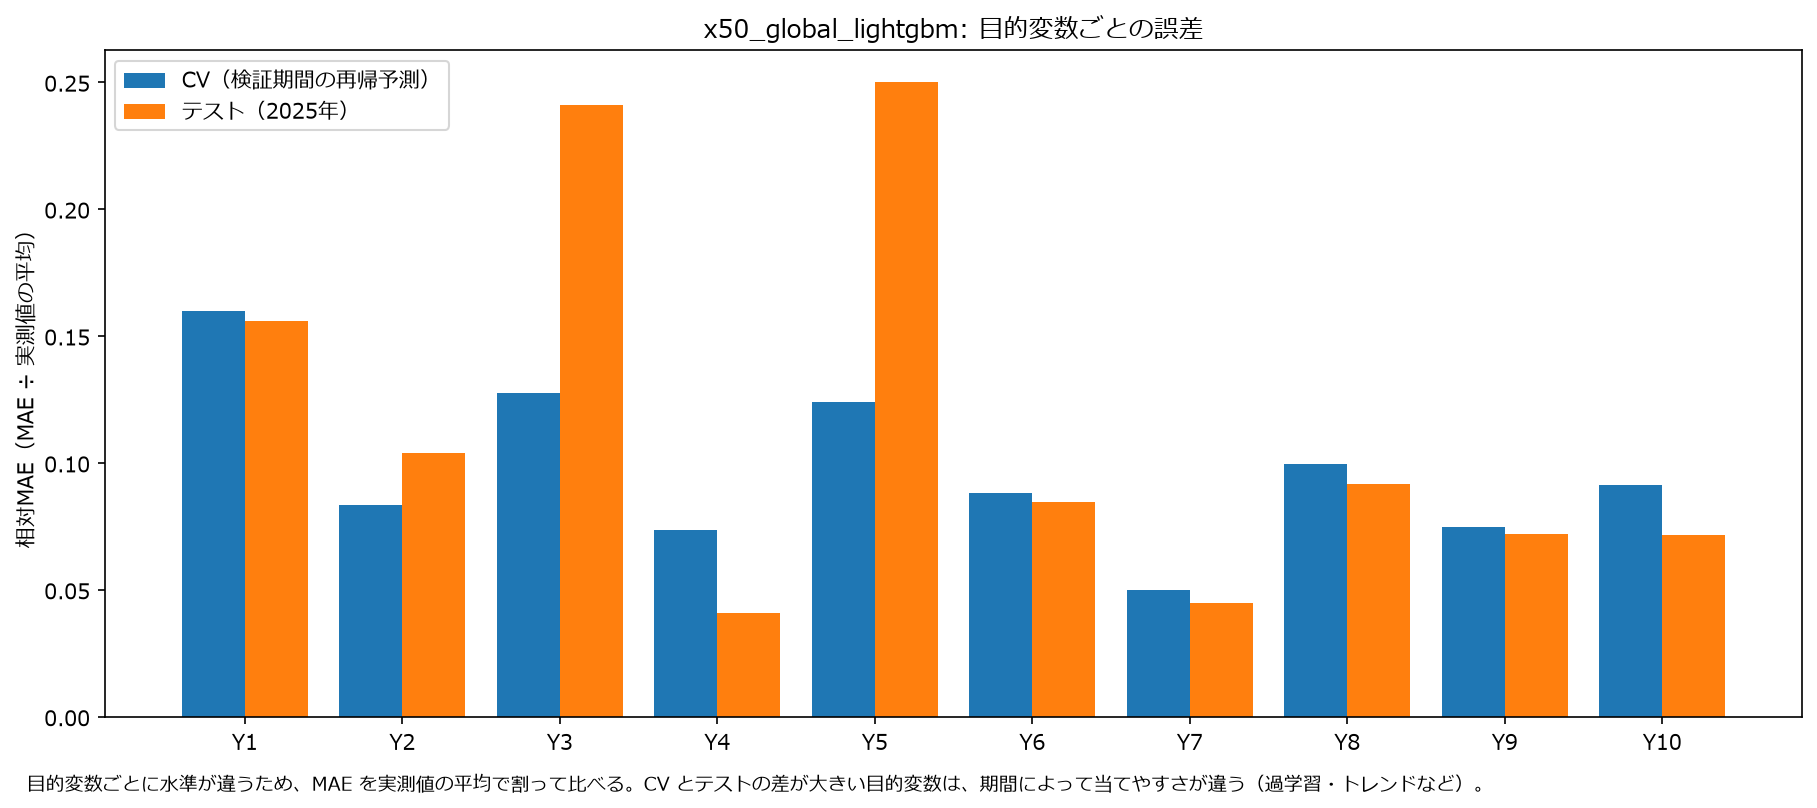

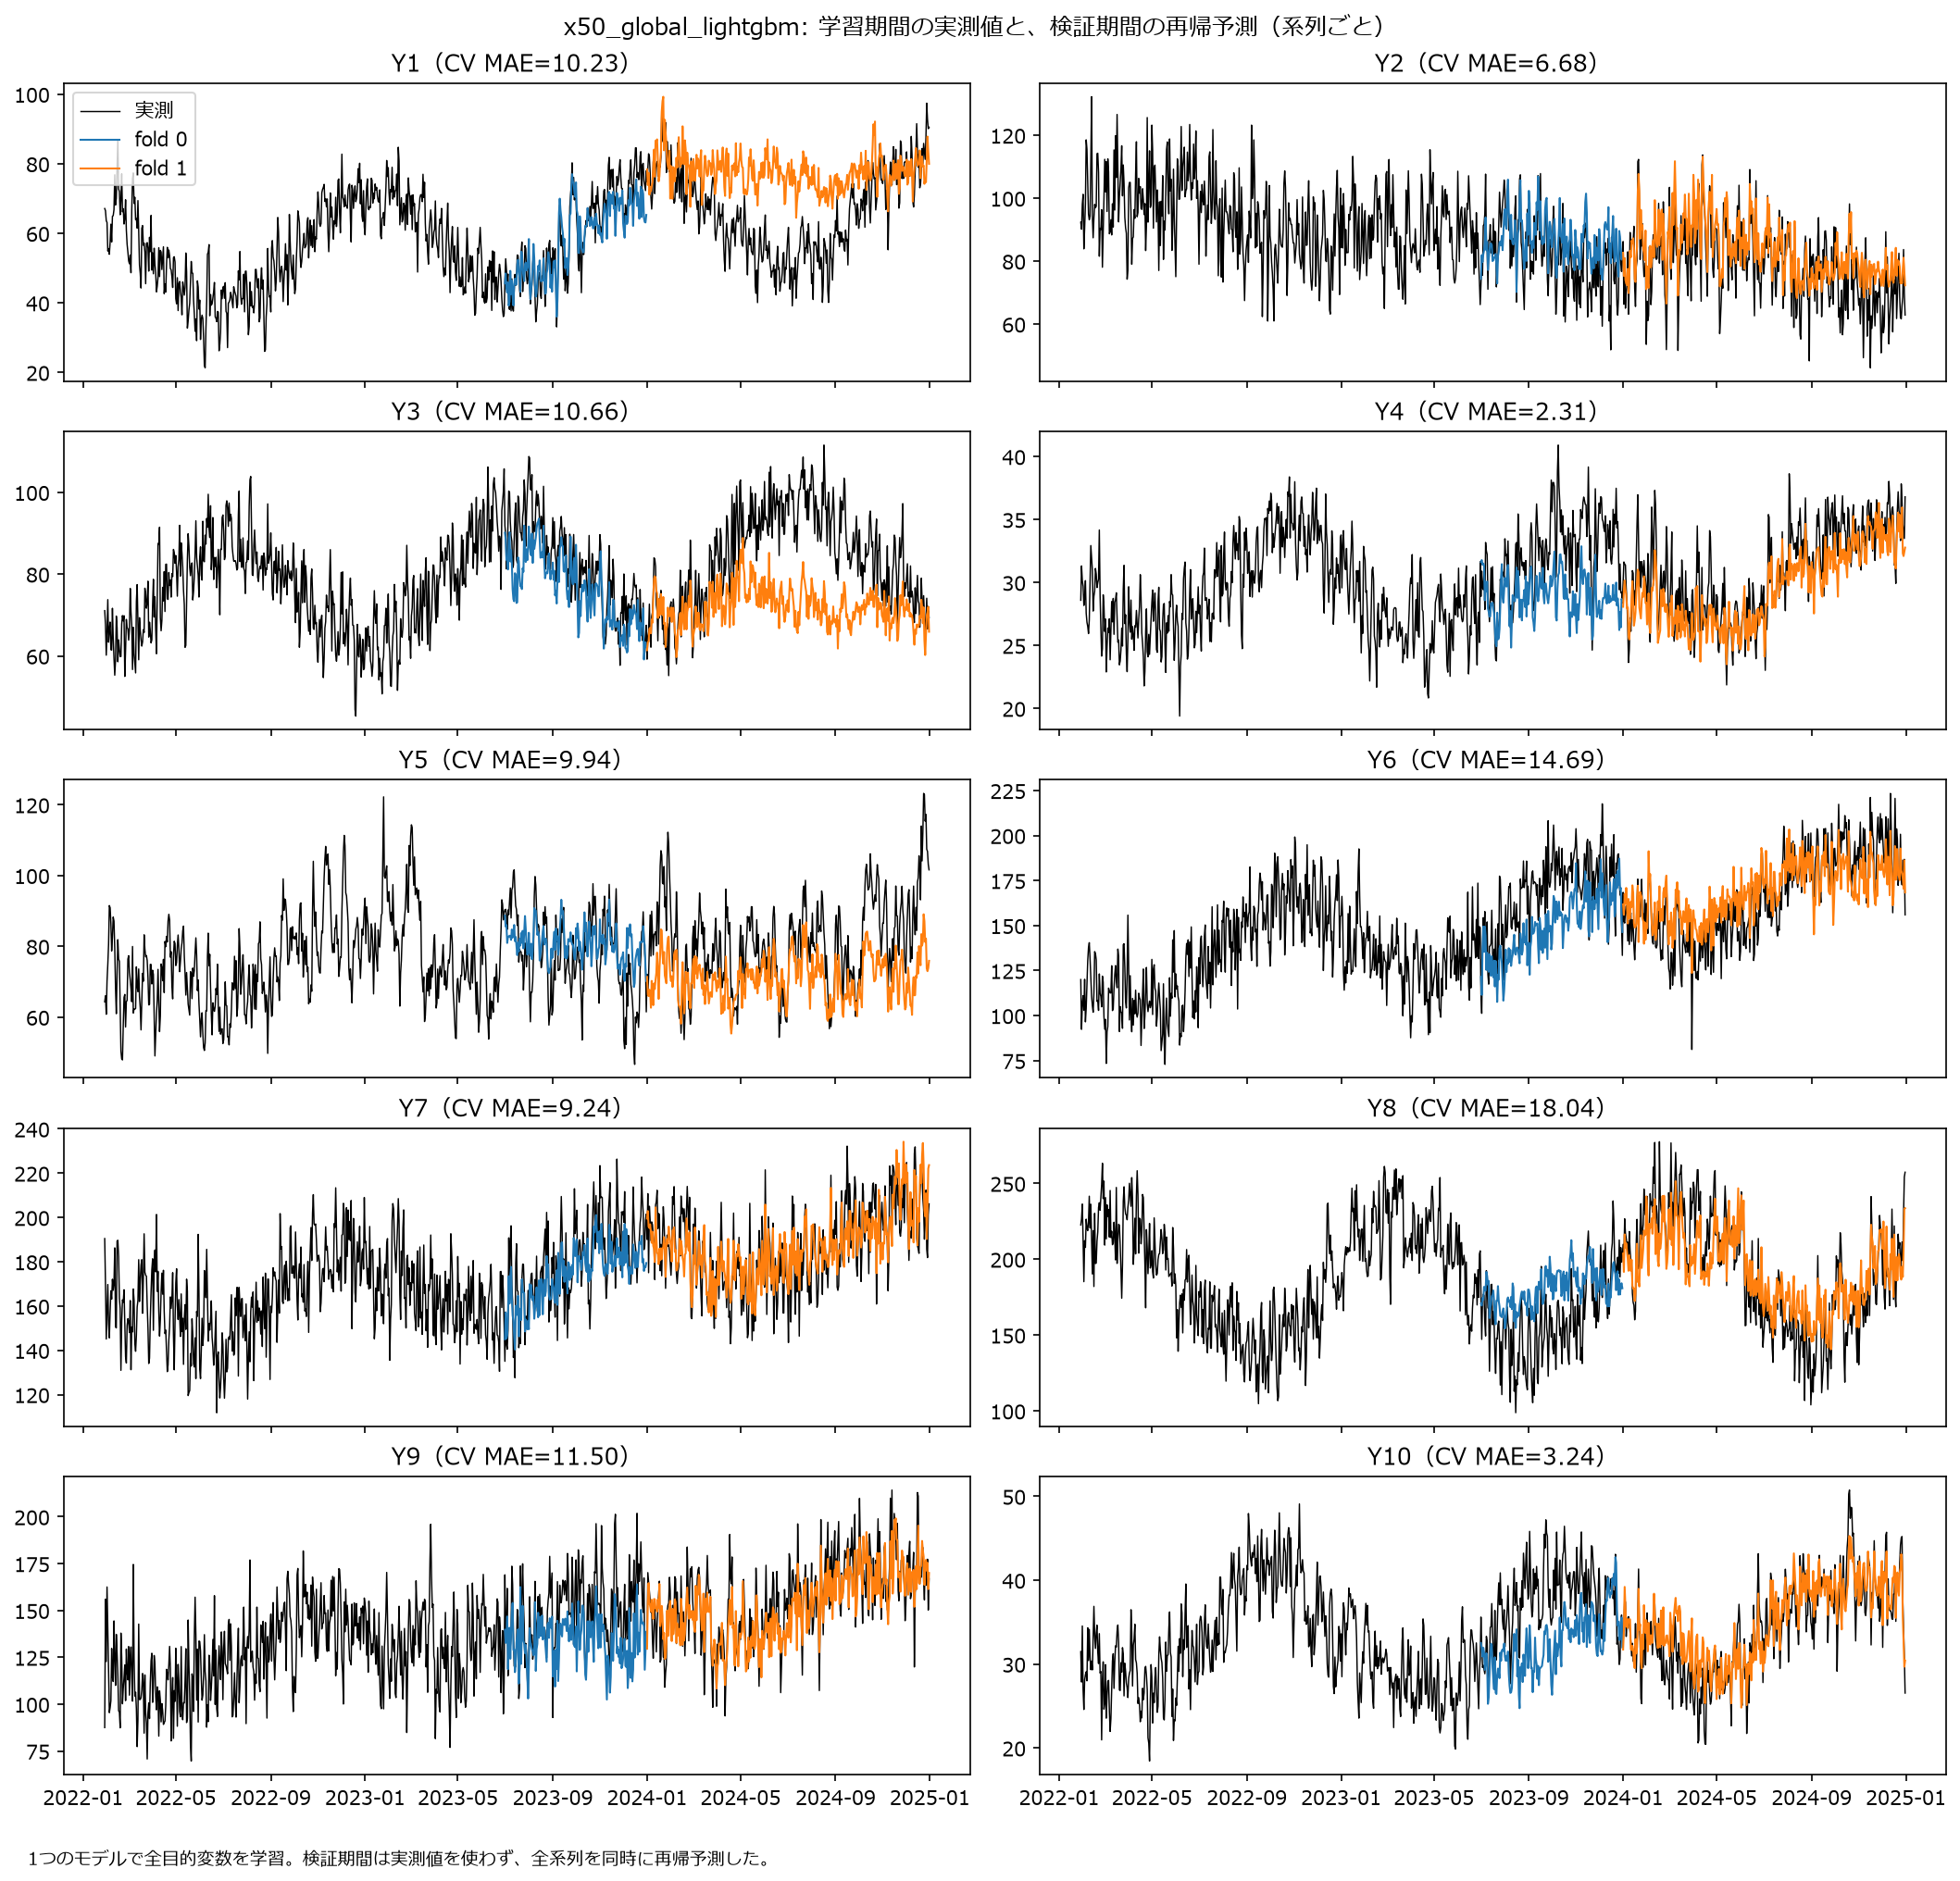

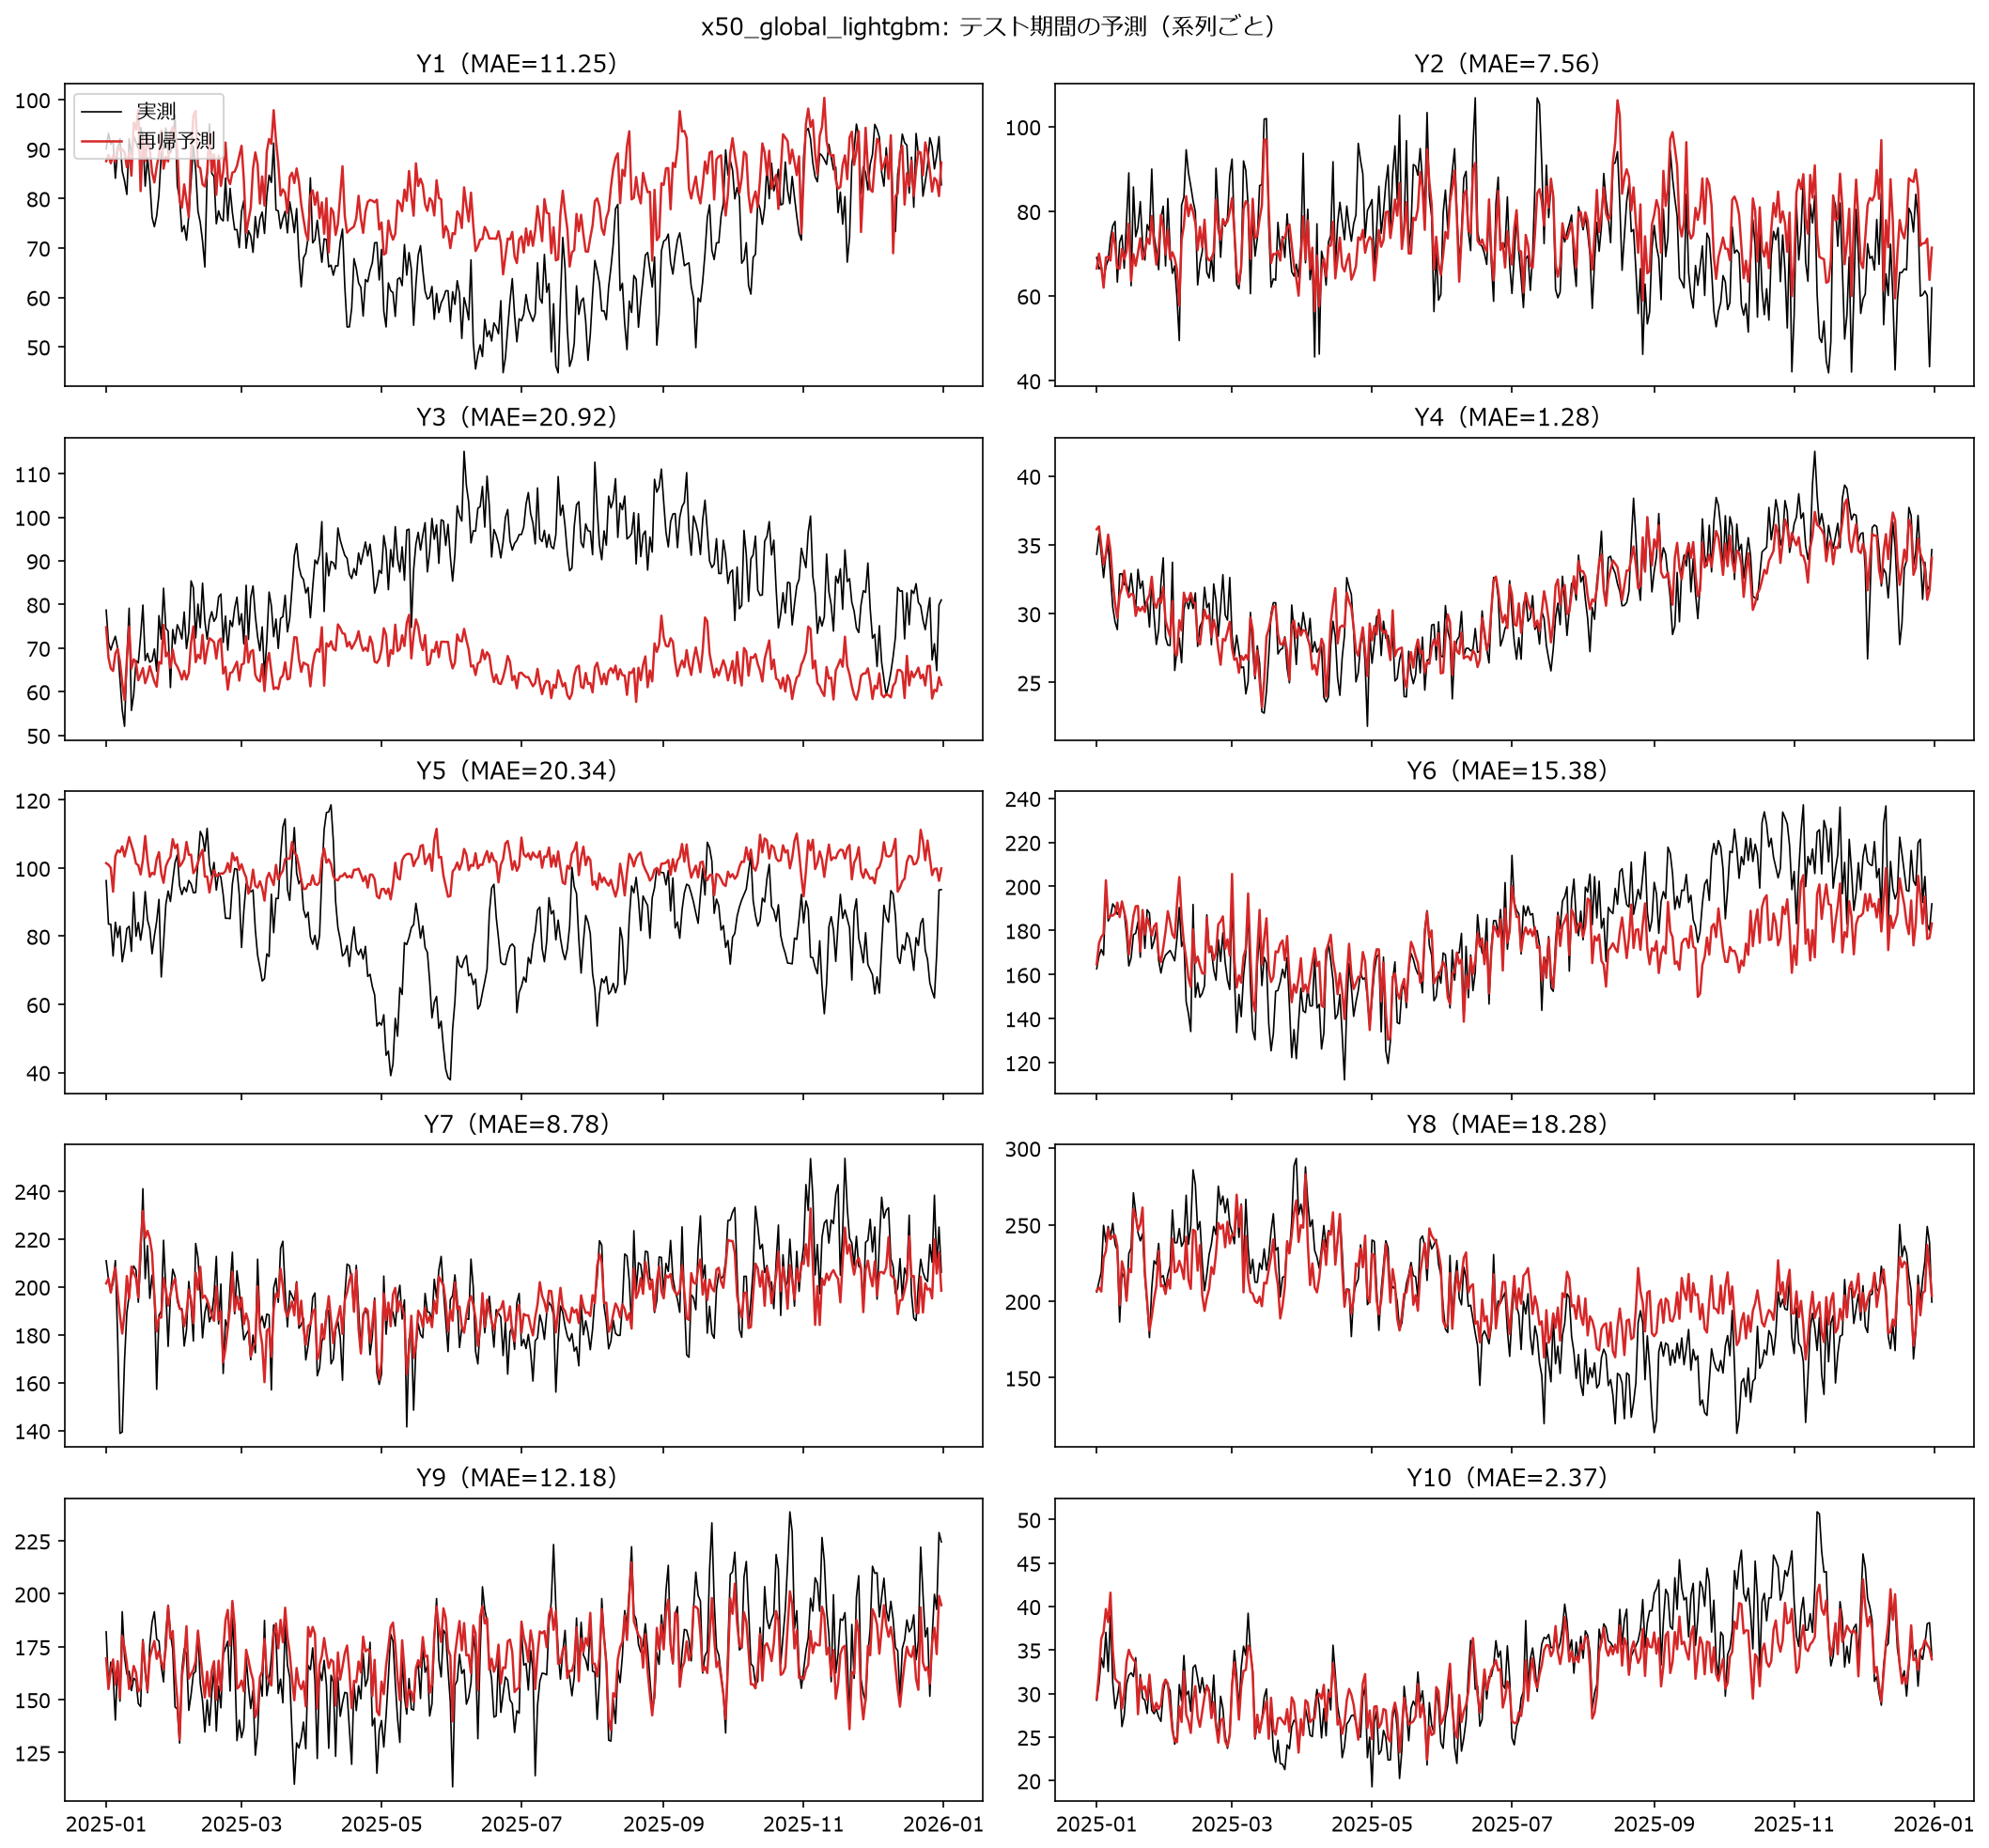

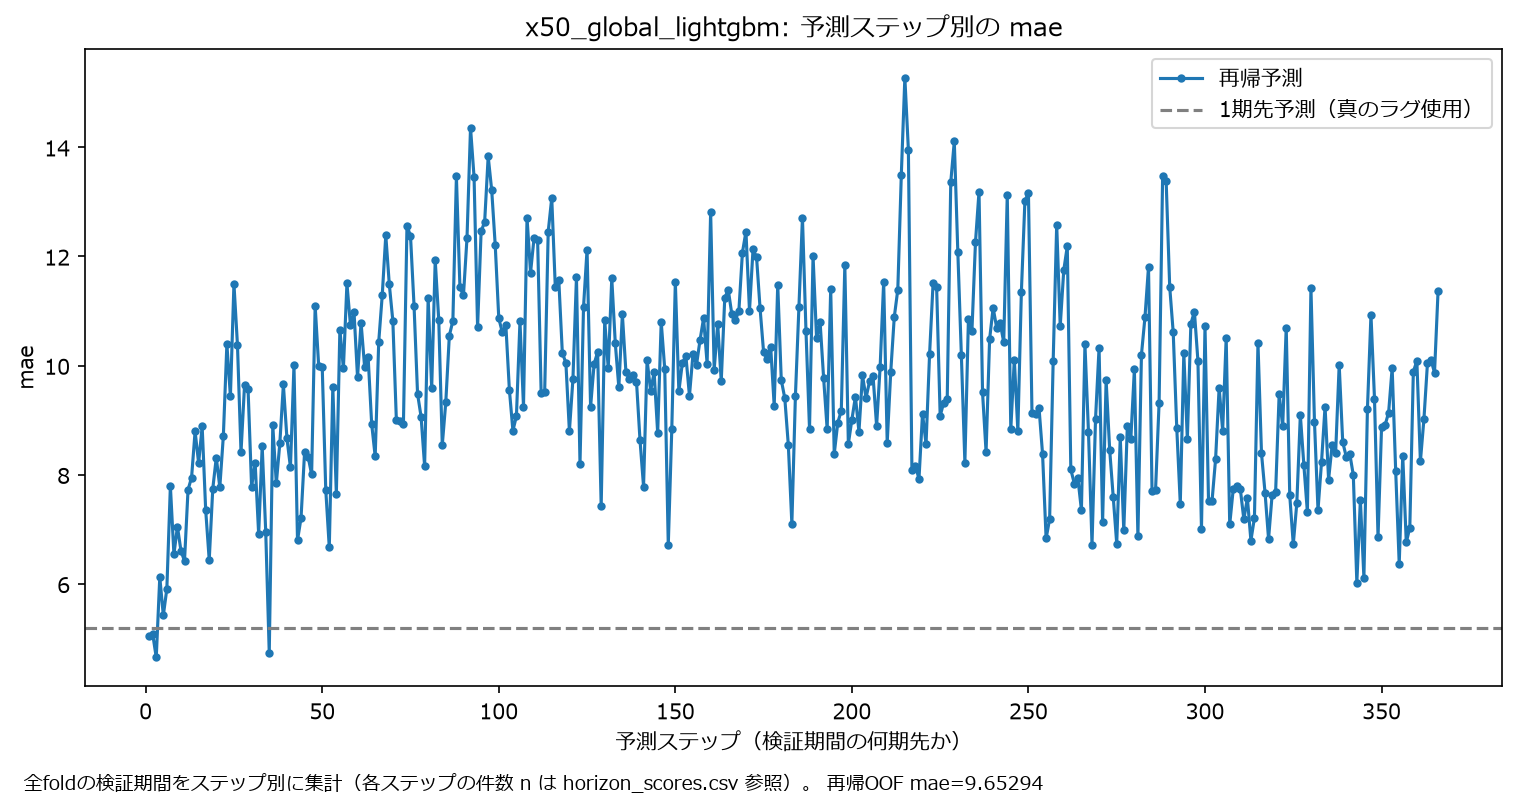

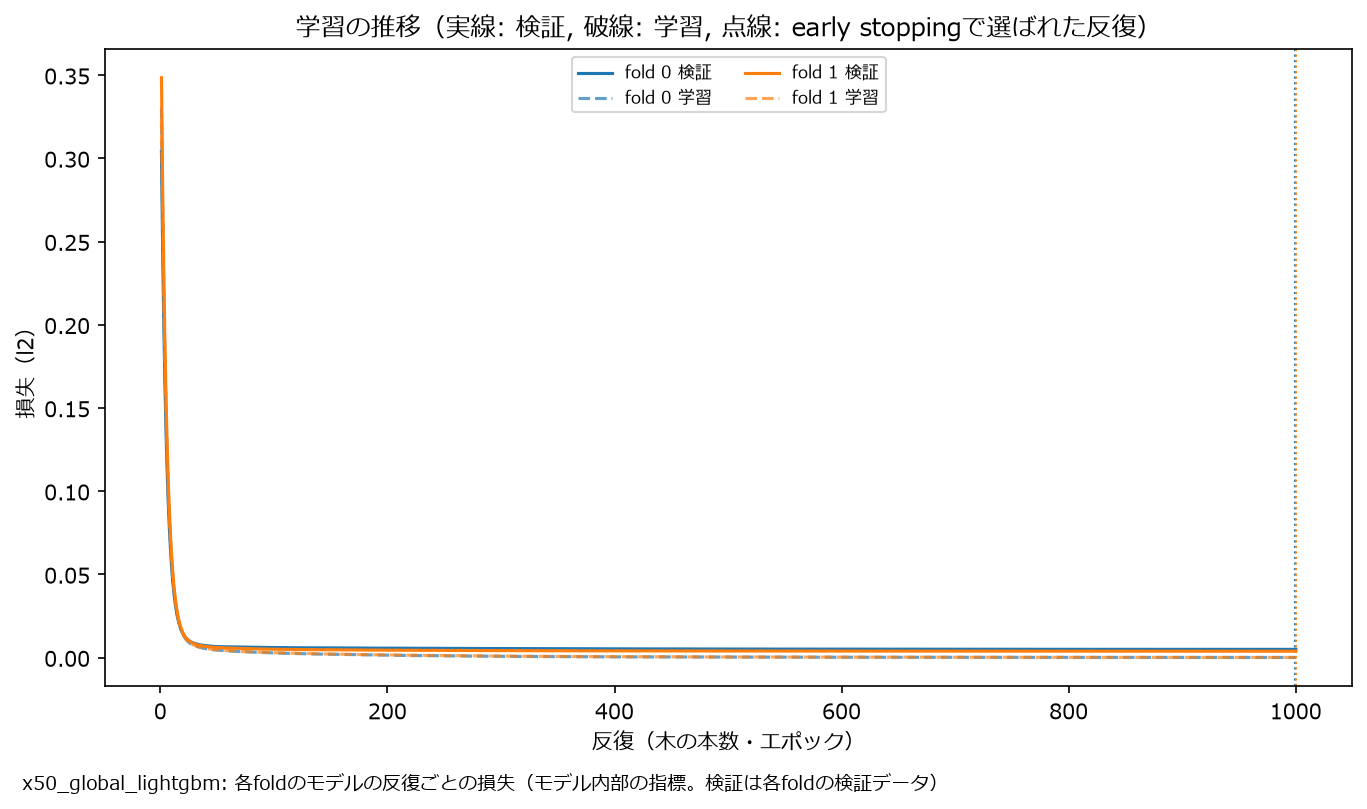

In [23]:
figures = out / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "training_overview.png"), width=1000))
display(Image(filename=str(figures / "test_overview.png"), width=1000))
display(Image(filename=str(out / "horizon_error.png"), width=800))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

## 9. SHAP によるモデル解釈

グローバルモデルを、各 fold の検証期間のデータで説明した SHAP 値（OOF SHAP）。モデルは目的変数の対数を予測するため、
SHAP 値も対数の尺度。

- **全体の重要度・beeswarm:** 全系列の行をまとめたもの。`series` は系列ID（どの目的変数か）。
- **目的変数ごとの重要度:** SHAP 値を行の系列で分けて平均し、目的変数ごとに合計1の割合にしたもの（004 の図と同じ形）。
  目的変数ごとに効く説明変数を、1つのモデルがどれだけ区別できているかを見る。

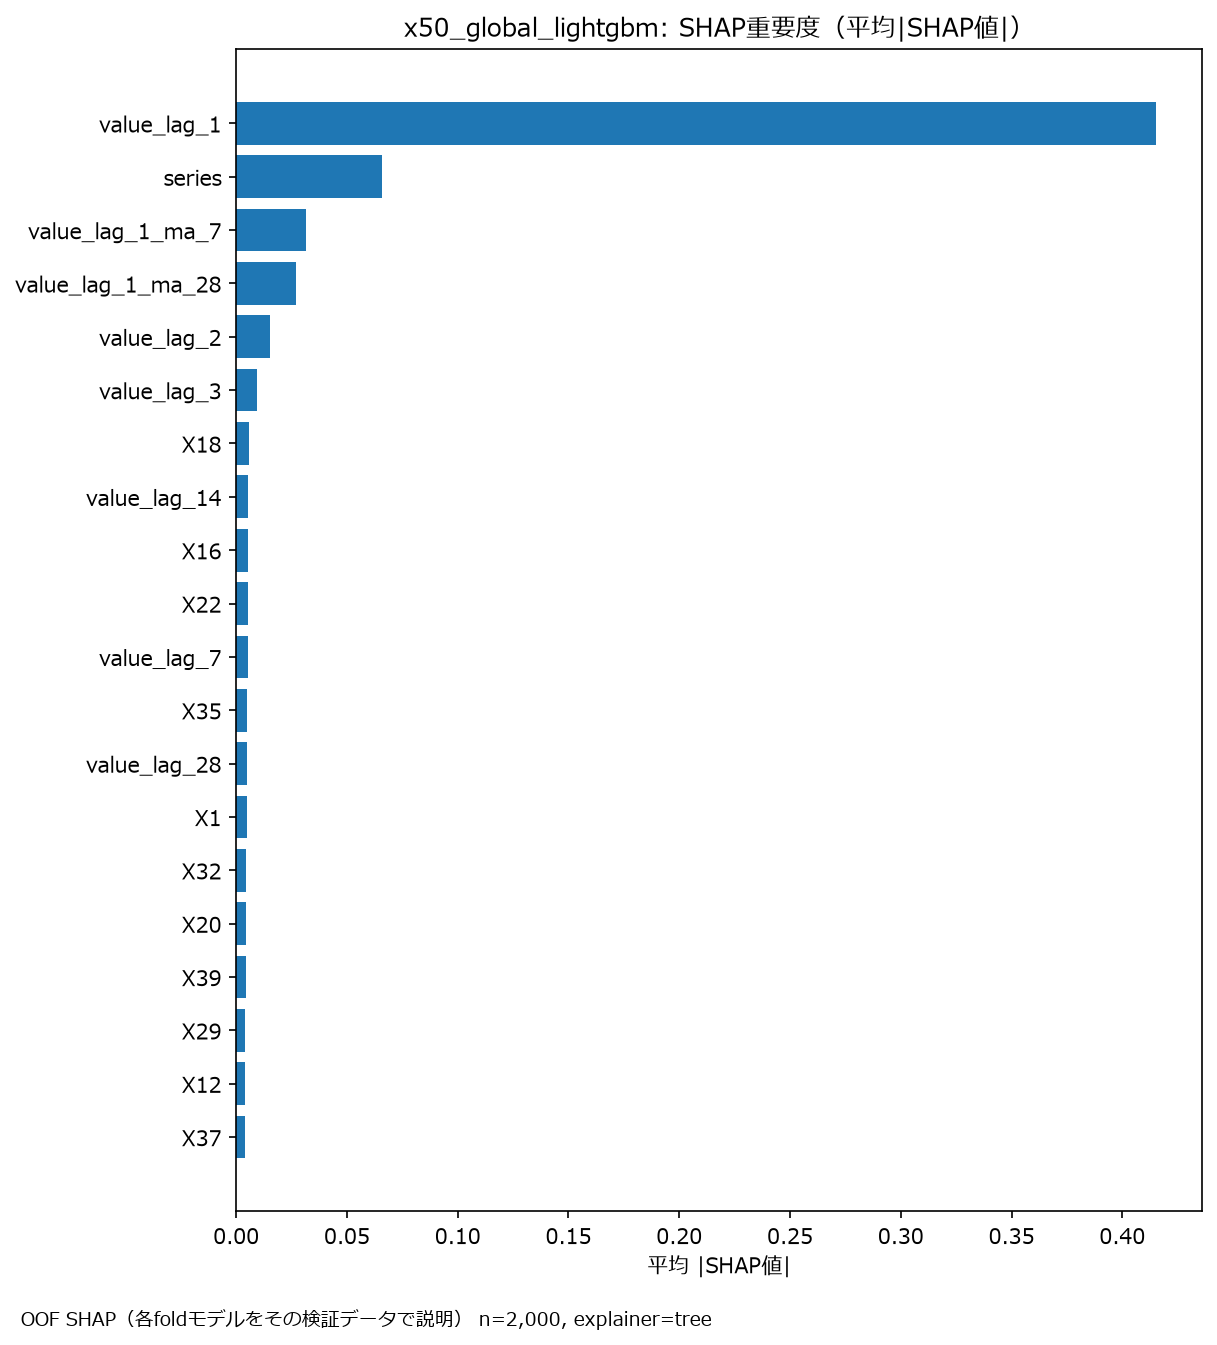

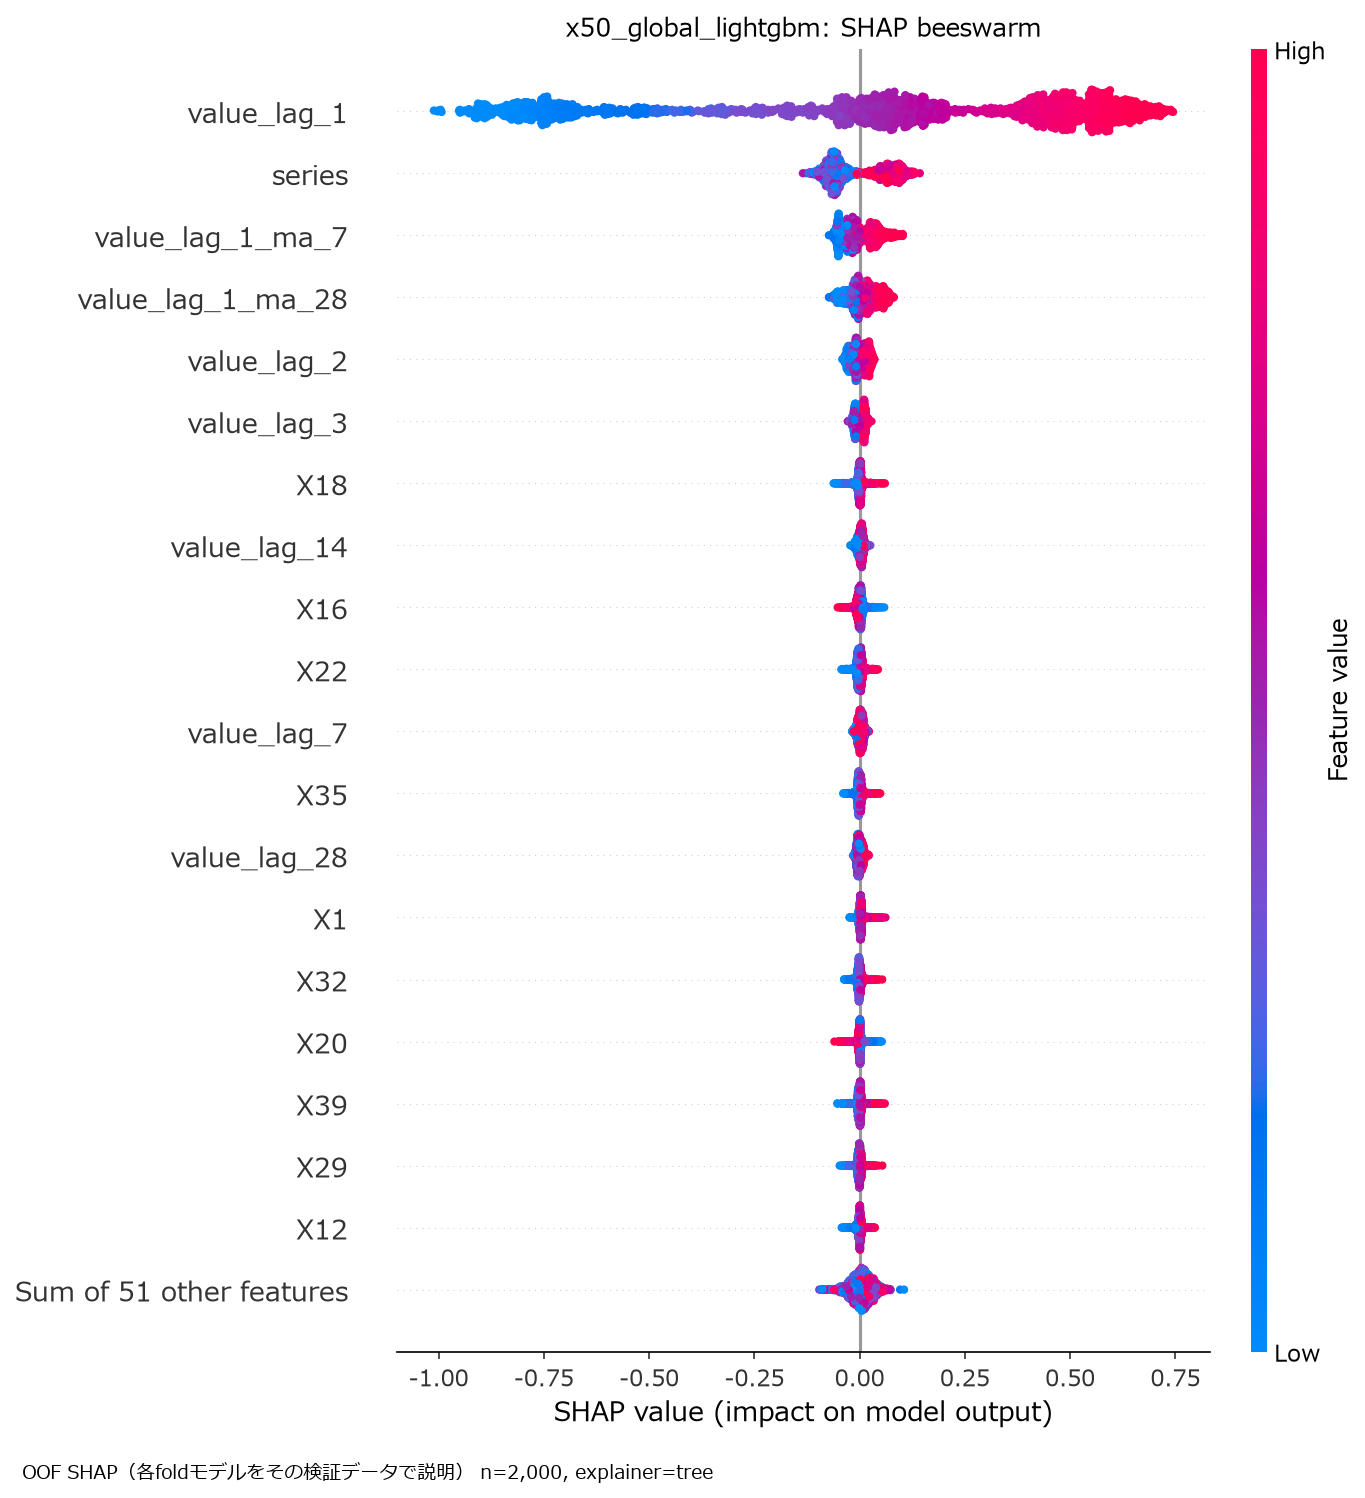

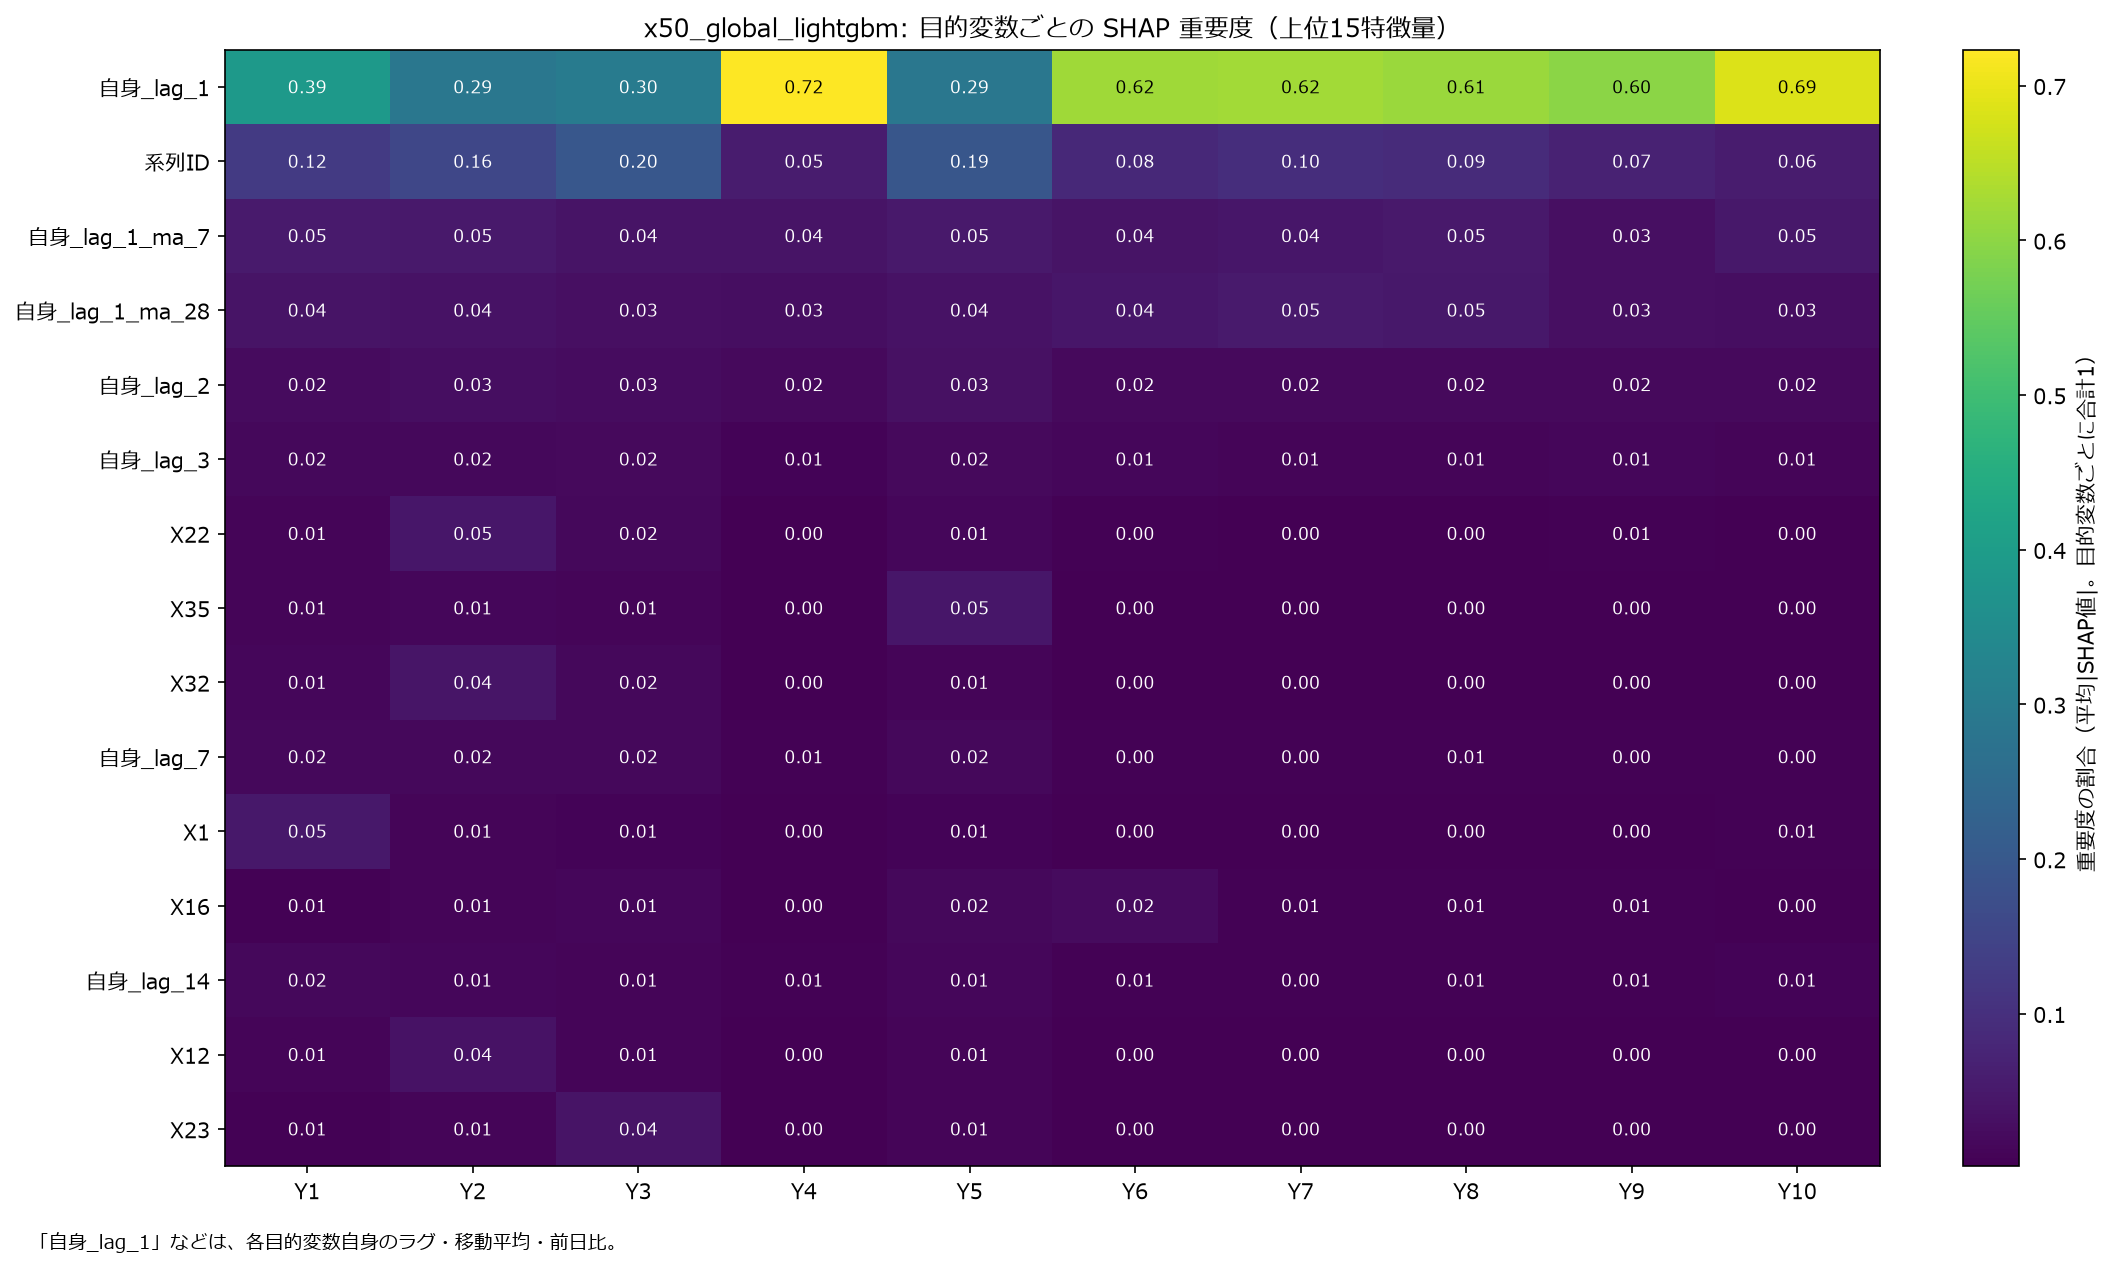

In [24]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(figures / "shap_overview.png"), width=1000))

## 10. 個別モデル（004 / 006）との比較

`004_train_predict_x50.ipynb`・`006_pipeline_x50.ipynb`（またはスクリプト `train_predict_x50.py`）の、同じモデルの最新の要約
（`outputs/experiments/x50_{モデル名}_summary/` の最新の実行）があれば、目的変数ごとの MAE を並べて比べる。

004 の要約: outputs/experiments/x50_lightgbm_summary/20261021_221125/summary.csv


,target,test_mae_個別モデル,test_mae_グローバル,差（グローバル − 個別）
0,Y1,3.563,11.253,7.690
1,Y2,4.690,7.560,2.871
2,Y3,21.466,20.923,-0.543
3,Y4,1.210,1.279,0.069
4,Y5,6.534,20.336,13.802
5,Y6,10.610,15.378,4.767
6,Y7,8.459,8.779,0.320
7,Y8,10.186,18.276,8.090
8,Y9,10.632,12.180,1.548
9,Y10,1.654,2.374,0.720


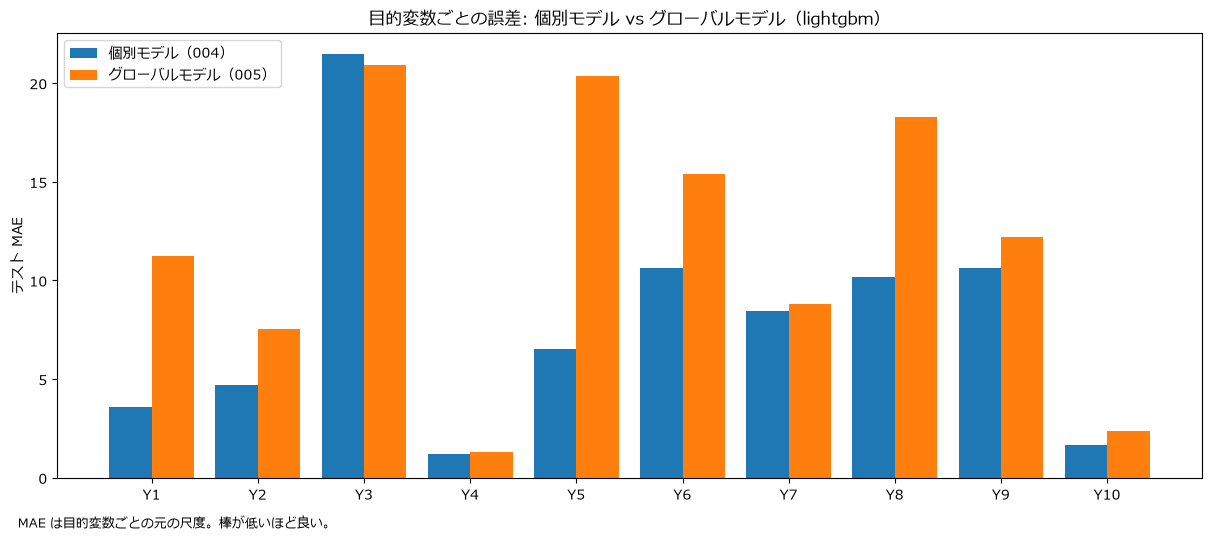

グローバルモデルの方が良い目的変数: 1 / 10
図: outputs/experiments/x50_global_lightgbm/20261022_000807_498038/figures/comparison_with_004.png


In [25]:
summaries_004 = sorted(
    (outputs_dir() / "experiments" / f"x50_{MODEL}_summary").glob("*/summary.csv")
)
if COMPARE_WITH_004 and summaries_004:
    individual = pd.read_csv(summaries_004[-1])
    print(f"004 の要約: {shown(summaries_004[-1])}")
    metric = (
        "test_mae"
        if "test_mae" in summary.columns and "test_mae" in individual.columns
        else "cv_oof_mae"
    )
    comparison = individual[["target", metric]].merge(
        summary[["target", metric]], on="target", suffixes=("_個別モデル", "_グローバル")
    )
    comparison["差（グローバル − 個別）"] = (
        comparison[f"{metric}_グローバル"] - comparison[f"{metric}_個別モデル"]
    )
    display(comparison.round(3))

    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(comparison))
    ax.bar(positions - 0.2, comparison[f"{metric}_個別モデル"], 0.4, label="個別モデル（004）")
    ax.bar(
        positions + 0.2, comparison[f"{metric}_グローバル"], 0.4, label="グローバルモデル（005）"
    )
    ax.set_xticks(positions, comparison["target"])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("テスト MAE" if metric == "test_mae" else "CV MAE（再帰予測）")
    ax.set_title(f"目的変数ごとの誤差: 個別モデル vs グローバルモデル（{MODEL}）")
    ax.legend(loc="upper left")
    add_caption(fig, "MAE は目的変数ごとの元の尺度。棒が低いほど良い。")
    comparison_path = figures / "comparison_with_004.png"
    fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    better = int((comparison["差（グローバル − 個別）"] < 0).sum())
    print(f"グローバルモデルの方が良い目的変数: {better} / {len(comparison)}")
    print(f"図: {shown(comparison_path)}")
else:
    print("004 の結果が無いため比較を飛ばします（先に 004 を実行してください）")

## 11. 1つの目的変数の詳細（`DETAIL_TARGET`）

`modeling.evaluation` が系列ごとに作る、時系列の残差診断（推移・ヒストグラム・Q-Q・ACF/PACF・検定結果）。
再帰予測（recursive）の残差は誤差が積み重なるため自己相関が出やすい。モデルが取りこぼした過去の情報が無いかは、
1日先予測（onestep）の残差で判断する。

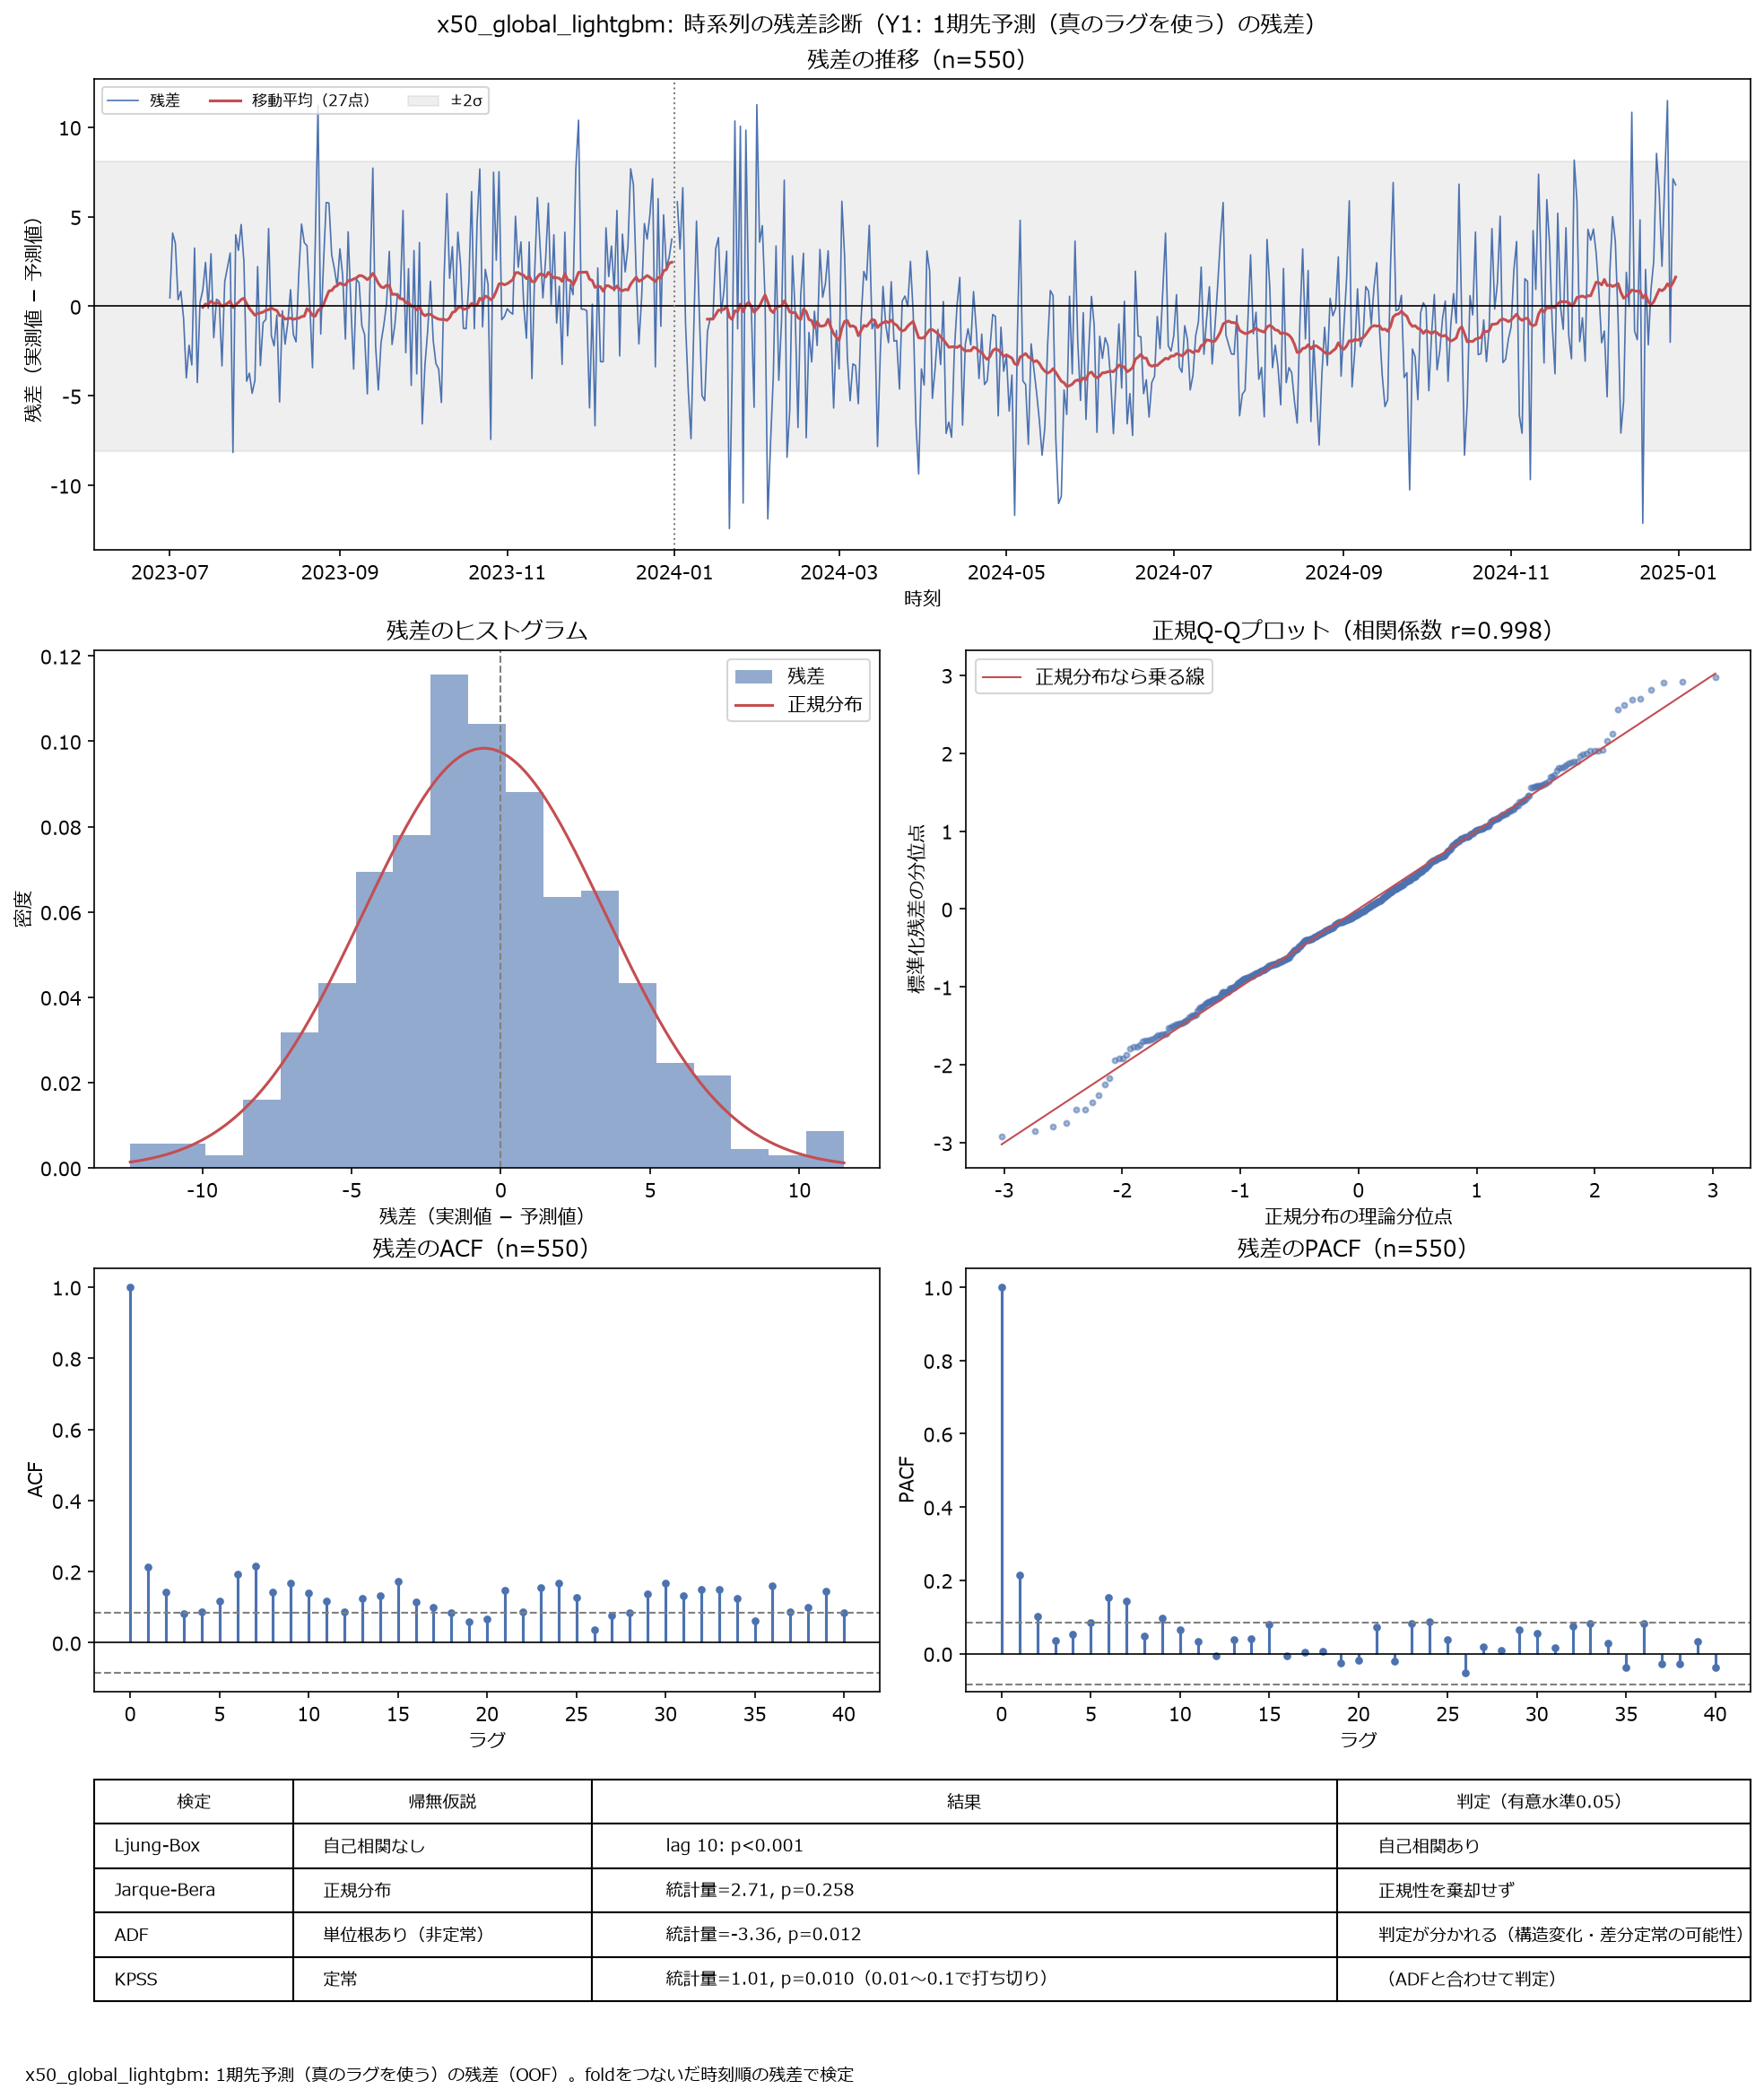

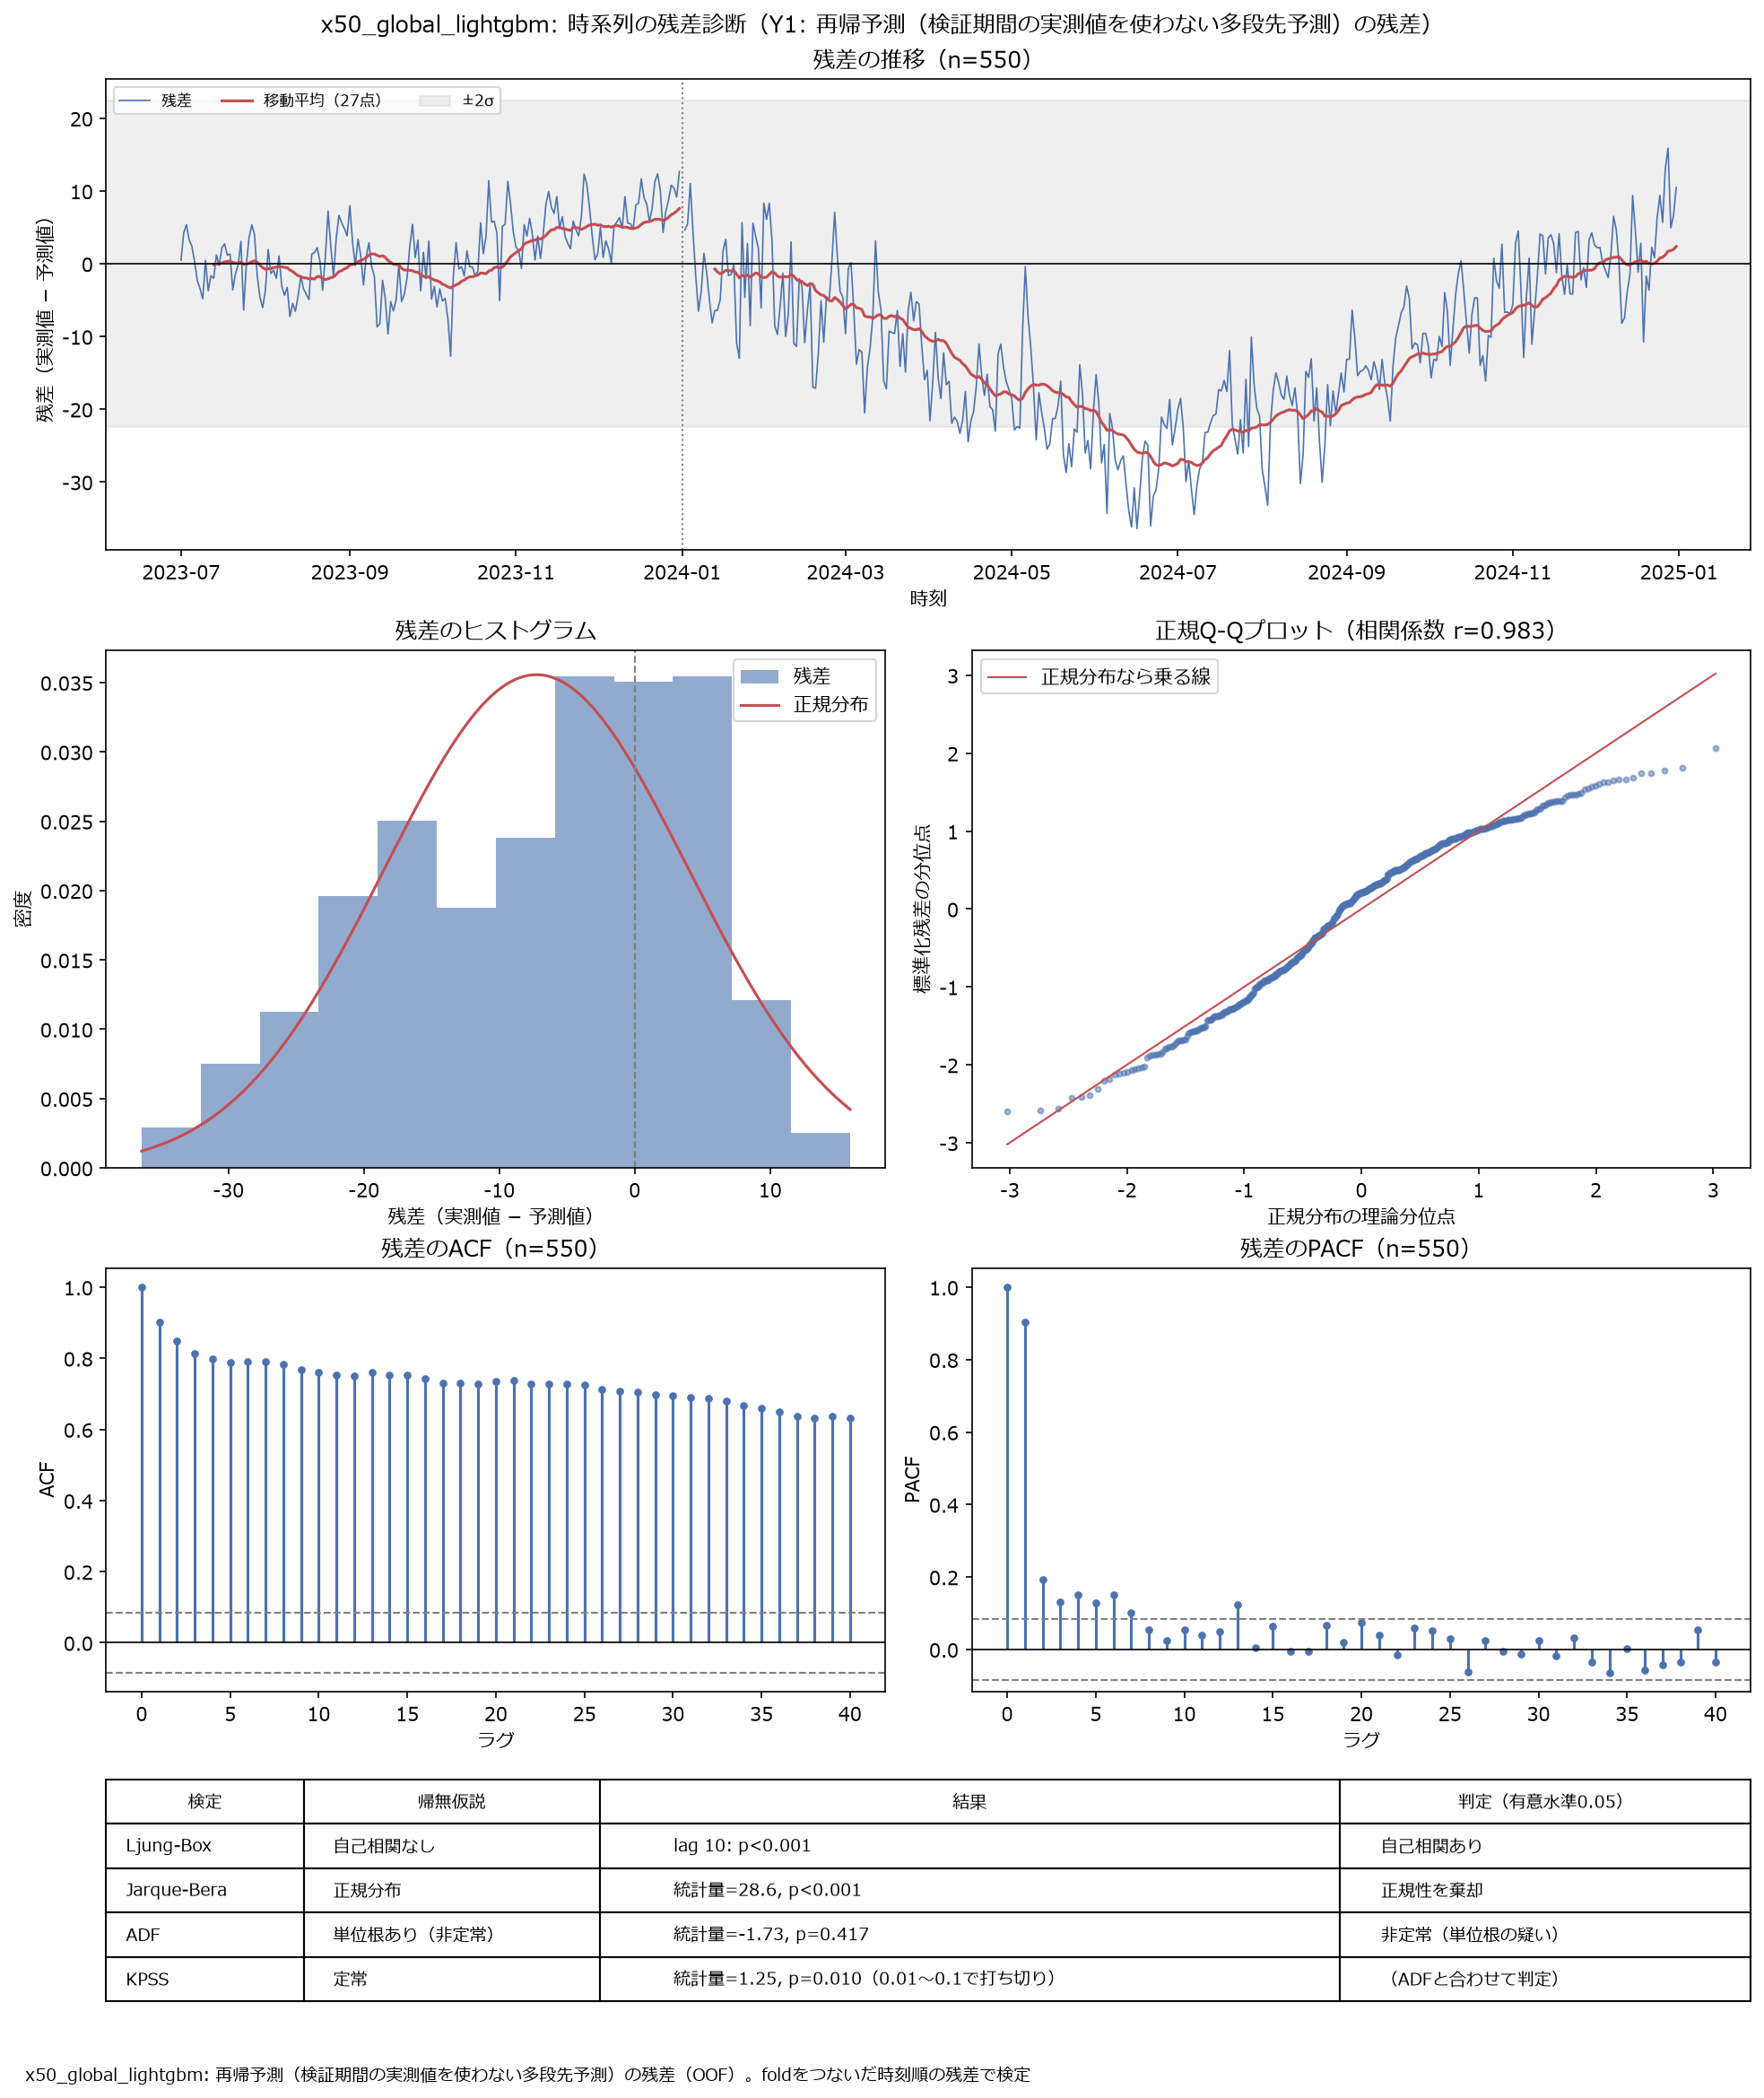

,date,series,pred,actual
0,2025-01-01,Y1,87.550281,90.004803
10,2025-01-02,Y1,88.823312,93.198048
20,2025-01-03,Y1,87.129498,90.977363
30,2025-01-04,Y1,88.734114,91.699246
40,2025-01-05,Y1,87.404967,84.084049


In [26]:
for kind in ("onestep", "recursive"):
    path = out / "evaluation" / f"residual_diagnostics__{kind}__{DETAIL_TARGET}.png"
    display(Image(filename=str(path), width=850))
detail = run.predictions[run.predictions[SERIES_COL] == DETAIL_TARGET]
detail.head()

## まとめ

- 前半で、生データの目的変数・日付・説明変数のそれぞれに `src/feature_engineering` の前処理をかけ（学習が必要なものは
  学習データだけで fit）、前処理済みの CSV を出力した。
- 後半で、目的変数 Y1〜Y10 を縦持ちにし、系列IDを特徴量に加えた1つのモデル（グローバルモデル）で学習・再帰予測した。
  各行の目的変数の特徴量は、その目的変数自身のラグ等だけから作っている（前半のCSVの値と一致することを確認）。
- 前処理と再帰予測のそれぞれで、入力を書き換えるリークの確認を行った。CV は本番と同じ条件（検証期間の実測値を使わない、
  全系列同時の再帰予測）で評価している。
- ログはファイル（`outputs/logs/`、出力ディレクトリの `run.log`）と MLflow（全体・目的変数ごとの MAE、図、予測）に残している。

**注意点**

- 学習の早期終了・チューニングの指標（MAE）は全系列の行をまとめて計算するため、水準の高い目的変数の誤差の影響が大きい。
- 目的変数ごとに効く説明変数が違うデータでは、グローバルモデルはその違いを系列IDとの組み合わせで学ぶ必要があり、
  個別モデルより不利になりやすい（ダミーデータでは Yk に Xk 系だけが効く）。似た性質の目的変数が多い・各目的変数の
  データが少ない場合は、グローバルモデルが有利になりやすい。
- SHAP は検証期間（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使った期間が違う。